# Weather Forecast API & Time-Series EDA

## Project Overview

This project collects and analyzes ten years of daily historical weather data for Cairo, Egypt, using the NASA POWER API.

## Project Objectives

* Retrieve historical daily weather data from a public API.
* Store the raw API response in JSON format.
* Prepare and clean the weather dataset.
* Validate timestamps, frequency, missing values, duplicates, and measurement units.
* Explore temperature, precipitation, wind speed, and relative humidity patterns.
* Analyze long-term trends, seasonal patterns, and temporal dependencies.
* Evaluate stationarity and investigate unusual weather observations.
* Produce a cleaned CSV dataset and a concise analytical summary.

## Study Period

January 1, 2016 – December 31, 2025.

## Data Source

NASA Prediction of Worldwide Energy Resources (POWER) Daily API.


In [9]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import json

## 1. Configure the Weather API

We will use the NASA POWER Daily API to retrieve ten years of historical daily weather data for Cairo, Egypt, covering the period from January 1, 2016, to December 31, 2025.

The dataset will include daily maximum, minimum, and mean temperatures, precipitation, wind speed, and relative humidity.

The collected data will be used to investigate long-term trends, seasonal variations, temporal dependencies, and weather patterns through Time-Series Exploratory Data Analysis (EDA).


In [10]:
url = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M",
    "community": "AG",
    "longitude": 31.2357,
    "latitude": 30.0444,
    "start": "20160101",
    "end": "20251231",
    "format": "JSON"
}

In [11]:
response = requests.get(url, params=params, timeout=120)

print("Status Code:", response.status_code)

response.raise_for_status()

data = response.json()

print("Response received successfully!")
print("Available keys:", data.keys())

Status Code: 200
Response received successfully!
Available keys: dict_keys(['type', 'geometry', 'properties', 'header', 'messages', 'parameters', 'times'])


In [12]:
weather_data = data["properties"]["parameter"]

print("Data Type:", data["type"])
print("API Messages:", data["messages"])

print("\nAvailable Weather Parameters:")
print(list(weather_data.keys()))

print("\nNumber of records per parameter:")
for parameter, values in weather_data.items():
    print(f"{parameter}: {len(values)}")

Data Type: Feature
API Messages: []

Available Weather Parameters:
['T2M_MAX', 'T2M_MIN', 'T2M', 'PRECTOTCORR', 'WS10M', 'RH2M']

Number of records per parameter:
T2M_MAX: 3653
T2M_MIN: 3653
T2M: 3653
PRECTOTCORR: 3653
WS10M: 3653
RH2M: 3653


In [16]:
weather_data = data["properties"]["parameter"]

print("Data Type:", data["type"])
print("API Messages:", data["messages"])

print("\nAvailable Weather Parameters:")
print(list(weather_data.keys()))

print("\nNumber of records per parameter:")
for parameter, values in weather_data.items():
    print(f"{parameter}: {len(values)}")

print("\nFirst date:", list(weather_data["T2M_MAX"].keys())[0])
print("Last date:", list(weather_data["T2M_MAX"].keys())[-1])

Data Type: Feature
API Messages: []

Available Weather Parameters:
['T2M_MAX', 'T2M_MIN', 'T2M', 'PRECTOTCORR', 'WS10M', 'RH2M']

Number of records per parameter:
T2M_MAX: 3653
T2M_MIN: 3653
T2M: 3653
PRECTOTCORR: 3653
WS10M: 3653
RH2M: 3653

First date: 20160101
Last date: 20251231


In [17]:
weather_data = data["properties"]["parameter"]

first_date = list(weather_data["T2M_MAX"].keys())[0]
last_date = list(weather_data["T2M_MAX"].keys())[-1]

print("First date:", first_date)
print("Last date:", last_date)
print("Total daily records:", len(weather_data["T2M_MAX"]))

First date: 20160101
Last date: 20251231
Total daily records: 3653


## 2. Save the Raw API Response

Save the complete API response as a JSON file before performing any data cleaning or transformation.

This preserves the original weather data and API metadata for reproducibility and future reference.

In [18]:
with open("cairo_weather_raw.json", "w", encoding="utf-8") as file:
    json.dump(data, file, indent=4)

print("Raw API response saved successfully!")

Raw API response saved successfully!


## 3. Convert API Data into a DataFrame

Extract the daily weather observations from the API response and convert them into a Pandas DataFrame.

Each row represents one day, and each column represents a weather variable or the observation date.

In [21]:
weather_data = data["properties"]["parameter"]

weather_data_df= pd.DataFrame(weather_data)

weather_data_df.index.name = "date"

weather_data_df = weather_data_df.reset_index()

weather_data_df.head()

,date,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M
0,20160101,13.03,5.53,10.08,0.90,5.49,66.37
1,20160102,14.35,3.52,8.31,0.01,3.08,63.88
2,20160103,18.01,4.84,10.54,0.02,3.97,67.52
3,20160104,19.33,6.47,11.99,0.00,4.22,63.10
4,20160105,20.48,7.56,12.78,0.00,5.43,47.29


## 4. Inspect the Dataset Structure

Inspect the dataset dimensions, column names, data types, and memory usage before cleaning.

This helps identify columns that need type conversion and provides an initial understanding of the dataset structure.

In [22]:
print("Dataset Shape:", weather_data_df.shape)

print("\nColumn Names:")
print(weather_data_df.columns.tolist())

print("\nData Types:")
print(weather_data_df.dtypes)

print("\nDataset Information:")
weather_data_df.info()

Dataset Shape: (3653, 7)

Column Names:
['date', 'T2M_MAX', 'T2M_MIN', 'T2M', 'PRECTOTCORR', 'WS10M', 'RH2M']

Data Types:
date               str
T2M_MAX        float64
T2M_MIN        float64
T2M            float64
PRECTOTCORR    float64
WS10M          float64
RH2M           float64
dtype: object

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         3653 non-null   str    
 1   T2M_MAX      3653 non-null   float64
 2   T2M_MIN      3653 non-null   float64
 3   T2M          3653 non-null   float64
 4   PRECTOTCORR  3653 non-null   float64
 5   WS10M        3653 non-null   float64
 6   RH2M         3653 non-null   float64
dtypes: float64(6), str(1)
memory usage: 199.9 KB


## 5. Convert the Date Column to Datetime

Convert the date column from strings into Pandas datetime values.

This enables proper chronological sorting, date-based filtering, resampling, and time-series analysis.

In [23]:
weather_data_df["date"] = pd.to_datetime(
    weather_data_df["date"],
    format="%Y%m%d"
)

print("Date Data Type:", weather_data_df["date"].dtype)
print("First Date:", weather_data_df["date"].min())
print("Last Date:", weather_data_df["date"].max())

Date Data Type: datetime64[us]
First Date: 2016-01-01 00:00:00
Last Date: 2025-12-31 00:00:00


## 6. Validate the Time Index

Check for duplicate dates, missing calendar days, and chronological ordering.

A complete daily time series is important for reliable rolling statistics, seasonal analysis, and time-series decomposition.

In [24]:
print("Duplicate Dates:", weather_data_df["date"].duplicated().sum())

expected_dates = pd.date_range(
    start="2016-01-01",
    end="2025-12-31",
    freq="D"
)

actual_dates = pd.DatetimeIndex(weather_data_df["date"])

missing_dates = expected_dates.difference(actual_dates)

print("Expected Number of Days:", len(expected_dates))
print("Actual Number of Rows:", len(weather_data_df))
print("Missing Dates:", len(missing_dates))
print("Chronologically Sorted:", weather_data_df["date"].is_monotonic_increasing)

Duplicate Dates: 0
Expected Number of Days: 3653
Actual Number of Rows: 3653
Missing Dates: 0
Chronologically Sorted: True


## 7. Missing Values Analysis

Inspect the dataset for missing values in each column and calculate their percentages.

This step helps assess data completeness before performing statistical analysis and visualizations.

In [25]:
missing_summary = pd.DataFrame({
    "Missing Values": weather_data_df.isnull().sum(),
    "Missing Percentage": weather_data_df.isnull().mean() * 100
})

missing_summary

,Missing Values,Missing Percentage
date,0,0.0
T2M_MAX,0,0.0
T2M_MIN,0,0.0
T2M,0,0.0
PRECTOTCORR,0,0.0
WS10M,0,0.0
RH2M,0,0.0


## 8. Duplicate Records Analysis

Check for completely duplicated rows in the weather dataset.

This step helps identify repeated records that could affect statistical summaries and subsequent analysis.

In [26]:
duplicate_rows = weather_data_df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_rows)

Number of Duplicate Rows: 0


## 9. Validate Weather Data Values

Inspect the numerical weather variables using descriptive statistics to identify potentially invalid or unusual values.

This step helps assess the ranges, distributions, and consistency of the weather measurements before performing exploratory data analysis.

In [27]:
weather_data_df.describe()

,date,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M
count,3653,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000
mean,2020-12-31 00:00:00,29.973893,15.285784,22.101204,0.388681,4.004744,52.686129
min,2016-01-01 00:00:00,11.670000,1.140000,6.530000,0.000000,1.110000,12.120000
25%,2018-07-02 00:00:00,22.860000,10.010000,15.650000,0.000000,3.310000,43.590000
50%,2020-12-31 00:00:00,30.680000,15.720000,22.740000,0.000000,3.970000,51.520000
75%,2023-07-02 00:00:00,37.210000,20.890000,28.860000,0.010000,4.630000,62.840000
max,2025-12-31 00:00:00,45.490000,27.600000,35.380000,95.480000,10.330000,88.720000
std,NaN,7.780887,5.971043,6.994020,2.937579,1.057053,13.257214


## 10. Descriptive Statistics of Weather Variables

Calculate descriptive statistics for the numerical weather variables, excluding the date column.

This provides a clearer overview of the distributions, central tendencies, variability, and ranges of the weather measurements.

In [28]:
weather_columns = [
    "T2M_MAX",
    "T2M_MIN",
    "T2M",
    "PRECTOTCORR",
    "WS10M",
    "RH2M"
]

weather_data_df[weather_columns].describe()

,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M
count,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000,3653.000000
mean,29.973893,15.285784,22.101204,0.388681,4.004744,52.686129
std,7.780887,5.971043,6.994020,2.937579,1.057053,13.257214
min,11.670000,1.140000,6.530000,0.000000,1.110000,12.120000
25%,22.860000,10.010000,15.650000,0.000000,3.310000,43.590000
50%,30.680000,15.720000,22.740000,0.000000,3.970000,51.520000
75%,37.210000,20.890000,28.860000,0.010000,4.630000,62.840000
max,45.490000,27.600000,35.380000,95.480000,10.330000,88.720000


## 11. Outlier Detection — Daily Maximum Temperature

Calculate the Interquartile Range (IQR) to identify potential outliers in daily maximum temperature.

The IQR method defines potential outliers as observations below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

These observations require investigation but are not necessarily errors.

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\4063739371.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


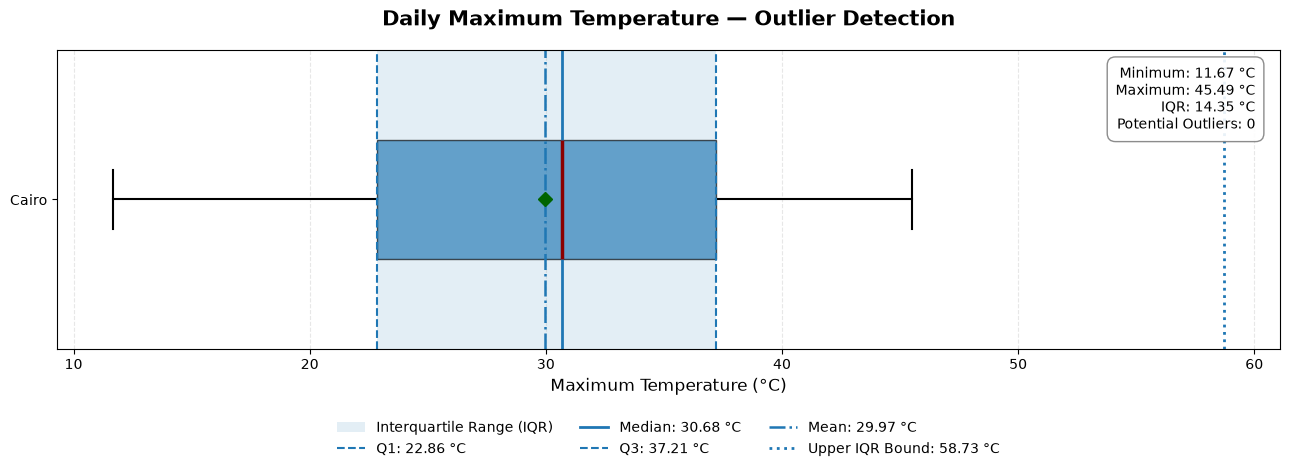

Q1: 22.86
Median: 30.68
Q3: 37.21
Mean: 29.97
IQR: 14.35
Lower Bound: 1.33
Upper Bound: 58.73
Minimum: 11.67
Maximum: 45.49
Potential Outliers: 0

Highest Temperature Observations:
      date  T2M_MAX
2024-06-14    45.49
2016-05-15    45.27
2024-06-15    45.27
2016-06-03    45.14
2019-05-23    45.07


In [34]:
import matplotlib.pyplot as plt

# Select the variable
column = "T2M_MAX"
temperature = weather_data_df[column].dropna()

# Calculate quartiles and IQR
Q1 = temperature.quantile(0.25)
Q2 = temperature.median()
Q3 = temperature.quantile(0.75)

IQR = Q3 - Q1

# Calculate IQR bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = weather_data_df[
    (weather_data_df[column] < lower_bound) |
    (weather_data_df[column] > upper_bound)
]

# Calculate mean
mean_temp = temperature.mean()

# Visualization
fig, ax = plt.subplots(figsize=(13, 5))

# Boxplot
ax.boxplot(
    temperature,
    vert=False,
    widths=0.4,
    showmeans=True,
    patch_artist=True,
    boxprops=dict(alpha=0.65),
    medianprops=dict(color="darkred", linewidth=2.5),
    meanprops=dict(
        marker="D",
        markerfacecolor="darkgreen",
        markeredgecolor="darkgreen",
        markersize=7
    ),
    whiskerprops=dict(linewidth=1.5),
    capprops=dict(linewidth=1.5),
    flierprops=dict(
        marker="o",
        markerfacecolor="orange",
        markeredgecolor="black",
        markersize=5,
        alpha=0.7
    )
)

# Highlight the interquartile range
ax.axvspan(
    Q1,
    Q3,
    alpha=0.12,
    label="Interquartile Range (IQR)"
)

# Reference lines
ax.axvline(
    Q1,
    linestyle="--",
    linewidth=1.5,
    label=f"Q1: {Q1:.2f} °C"
)

ax.axvline(
    Q2,
    linestyle="-",
    linewidth=2,
    label=f"Median: {Q2:.2f} °C"
)

ax.axvline(
    Q3,
    linestyle="--",
    linewidth=1.5,
    label=f"Q3: {Q3:.2f} °C"
)

ax.axvline(
    mean_temp,
    linestyle="-.",
    linewidth=1.8,
    label=f"Mean: {mean_temp:.2f} °C"
)

ax.axvline(
    upper_bound,
    linestyle=":",
    linewidth=2,
    label=f"Upper IQR Bound: {upper_bound:.2f} °C"
)

# Titles and labels
ax.set_title(
    "Daily Maximum Temperature — Outlier Detection",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Maximum Temperature (°C)", fontsize=12)
ax.set_yticks([1])
ax.set_yticklabels(["Cairo"])
ax.tick_params(axis="both", labelsize=10)

# Summary box
summary = (
    f"Minimum: {temperature.min():.2f} °C\n"
    f"Maximum: {temperature.max():.2f} °C\n"
    f"IQR: {IQR:.2f} °C\n"
    f"Potential Outliers: {len(outliers)}"
)

ax.text(
    0.98,
    0.95,
    summary,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

# Print statistics
print(f"Q1: {Q1:.2f}")
print(f"Median: {Q2:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"Mean: {mean_temp:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")
print(f"Minimum: {temperature.min():.2f}")
print(f"Maximum: {temperature.max():.2f}")
print(f"Potential Outliers: {len(outliers)}")

print("\nHighest Temperature Observations:")

print(
    weather_data_df.nlargest(5, column)[["date", column]]
    .to_string(index=False)
)



### Findings

* The IQR method identified no potential outliers in daily maximum temperature.
* The median daily maximum temperature was 30.68°C, while the mean was 29.97°C.
* The observed maximum temperature was 45.49°C on June 14, 2024.
* All recorded maximum temperatures fell within the calculated IQR bounds of 1.33°C and 58.73°C.
* Although no statistical outliers were detected, extreme observations may still require further investigation using domain knowledge.

**Conclusion:** No potential outliers were detected in the daily maximum temperature data using the IQR method.


## 12. Daily Temperature Trends

Analyze daily maximum, minimum, and mean temperatures in Cairo from 2016 to 2025.

Line plots will be used to visualize temperature variations over time and identify seasonal patterns and long-term trends.

This analysis helps us understand the behavior of the temperature data before exploring its suitability for time-series forecasting.


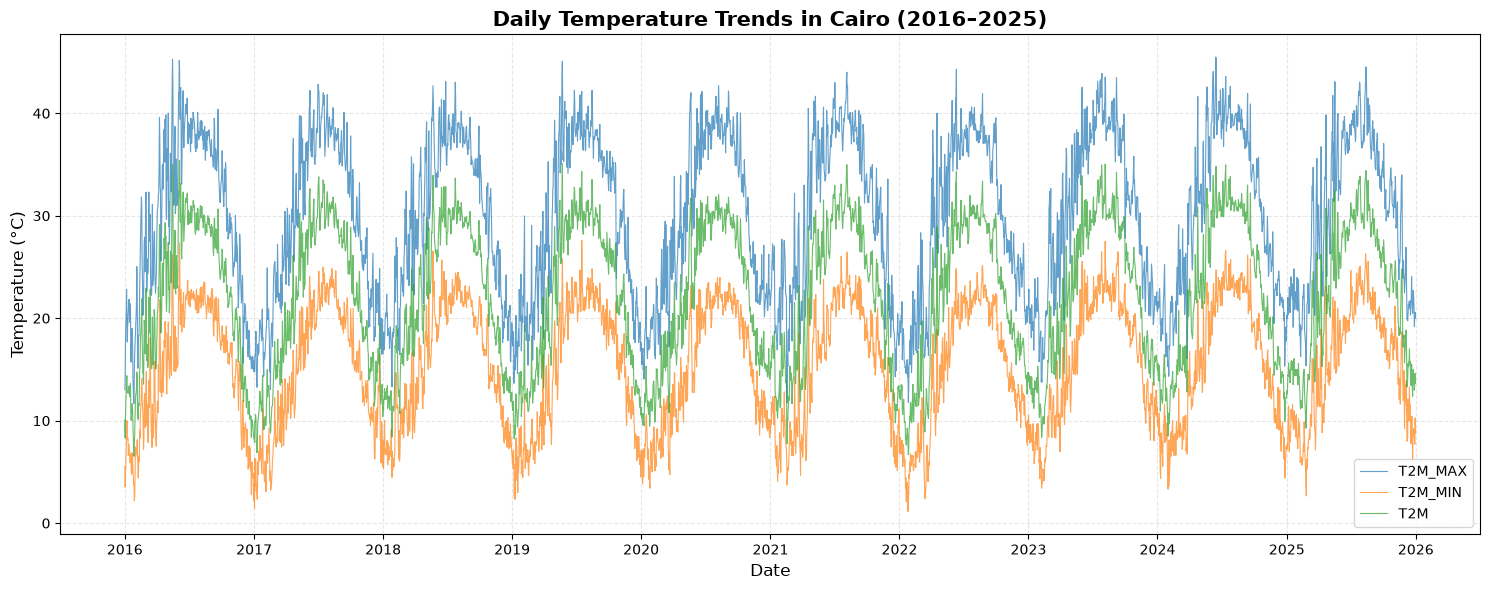

In [35]:
# Select temperature variables
temperature_columns = ["T2M_MAX", "T2M_MIN", "T2M"]

# Create the figure
fig, ax = plt.subplots(figsize=(15, 6))

# Plot daily temperatures
for column in temperature_columns:
    ax.plot(
        weather_data_df["date"],
        weather_data_df[column],
        label=column,
        alpha=0.7,
        linewidth=0.8
    )

# Add titles and labels
ax.set_title(
    "Daily Temperature Trends in Cairo (2016–2025)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Temperature (°C)", fontsize=12)

# Improve readability
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# Calculate yearly average temperatures
yearly_temperature = weather_data_df.groupby(
    weather_data_df["date"].dt.year
)[["T2M_MAX", "T2M_MIN", "T2M"]].mean()

print("Yearly Average Temperatures (°C):")
print(yearly_temperature.round(2).to_string())

print("\nOverall Temperature Statistics (°C):")
print(
    weather_data_df[["T2M_MAX", "T2M_MIN", "T2M"]]
    .agg(["mean", "min", "max"])
    .round(2)
    .to_string()
)

Yearly Average Temperatures (°C):
      T2M_MAX  T2M_MIN    T2M
date                         
2016    29.96    15.13  21.99
2017    29.12    14.60  21.31
2018    30.04    15.65  22.33
2019    29.81    15.07  21.92
2020    29.57    14.97  21.74
2021    30.32    15.28  22.24
2022    29.43    14.86  21.67
2023    30.48    15.98  22.67
2024    30.47    15.76  22.60
2025    30.53    15.56  22.54

Overall Temperature Statistics (°C):
      T2M_MAX  T2M_MIN    T2M
mean    29.97    15.29  22.10
min     11.67     1.14   6.53
max     45.49    27.60  35.38


## 13. Monthly Temperature Patterns

Analyze monthly temperature patterns in Cairo using daily weather observations collected from 2016 to 2025.

Monthly averages will be calculated for daily maximum, minimum, and mean temperatures to identify seasonal patterns and compare temperature variations throughout the year.

This analysis helps us understand the seasonality of the data before developing a weather forecasting model.


In [37]:
# Calculate average temperatures for each month across all years
monthly_temperature = (
    weather_data_df
    .groupby(weather_data_df["date"].dt.month)[
        ["T2M_MAX", "T2M_MIN", "T2M"]
    ]
    .mean()
)

# Rename month numbers
monthly_temperature.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Display results
print("Average Monthly Temperatures (°C):")
print(monthly_temperature.round(2).to_string())

Average Monthly Temperatures (°C):
     T2M_MAX  T2M_MIN    T2M
Jan    18.99     7.05  12.16
Feb    20.68     7.61  13.33
Mar    24.74     9.88  16.60
Apr    29.81    13.24  21.03
May    34.51    17.41  25.69
Jun    37.84    20.63  29.19
Jul    39.13    22.35  30.64
Aug    38.70    22.61  30.36
Sep    36.24    20.90  28.11
Oct    31.49    17.85  24.01
Nov    26.14    13.91  19.22
Dec    20.93     9.56  14.40


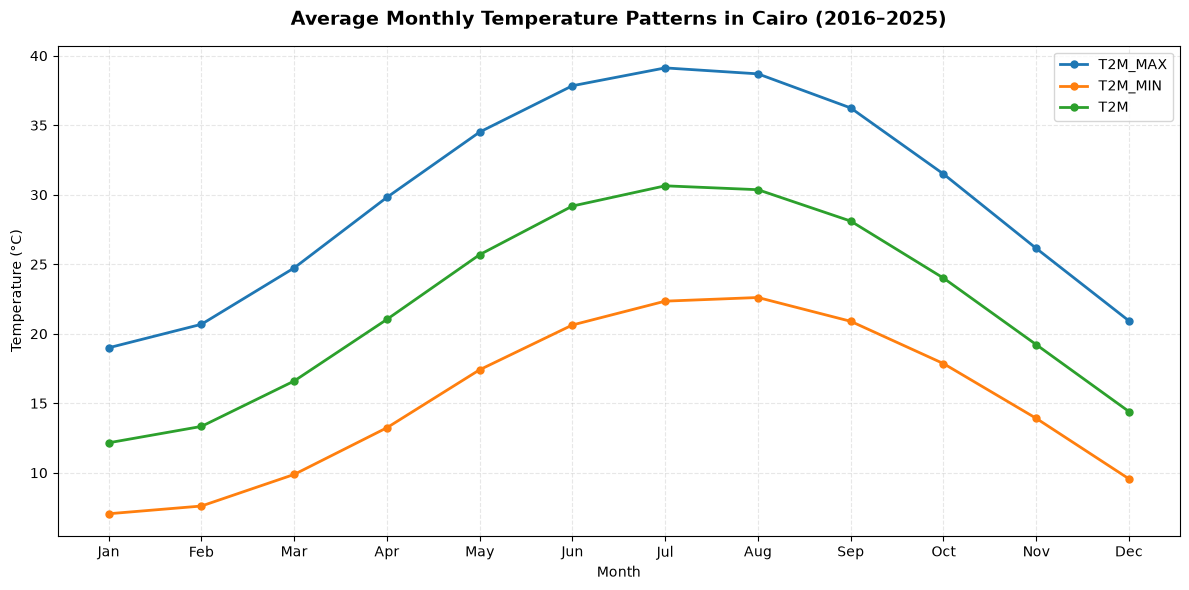

In [38]:
fig, ax = plt.subplots(figsize=(12, 6))

for column in ["T2M_MAX", "T2M_MIN", "T2M"]:
    ax.plot(
        monthly_temperature.index,
        monthly_temperature[column],
        marker="o",
        linewidth=2,
        markersize=5,
        label=column
    )

ax.set_title(
    "Average Monthly Temperature Patterns in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")

ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* July recorded the highest average daily maximum temperature (39.13°C) and mean temperature (30.64°C).
* August recorded the highest average daily minimum temperature (22.61°C).
* January was the coldest month, with an average daily mean temperature of 12.16°C.
* Temperatures generally increase from winter to summer and decrease from late summer through autumn and winter.
* The monthly averages reveal a clear seasonal pattern in Cairo's temperature data from 2016 to 2025.

**Conclusion:** Temperature seasonality is an important characteristic of this dataset and should be considered when developing a weather forecasting model.


## 13.1. Monthly Temperature Distribution (Boxplots)

Compare the distribution of daily mean temperature (`T2M`) for each calendar month using boxplots.

Unlike monthly averages, boxplots show the median, spread, and extreme values within each month.

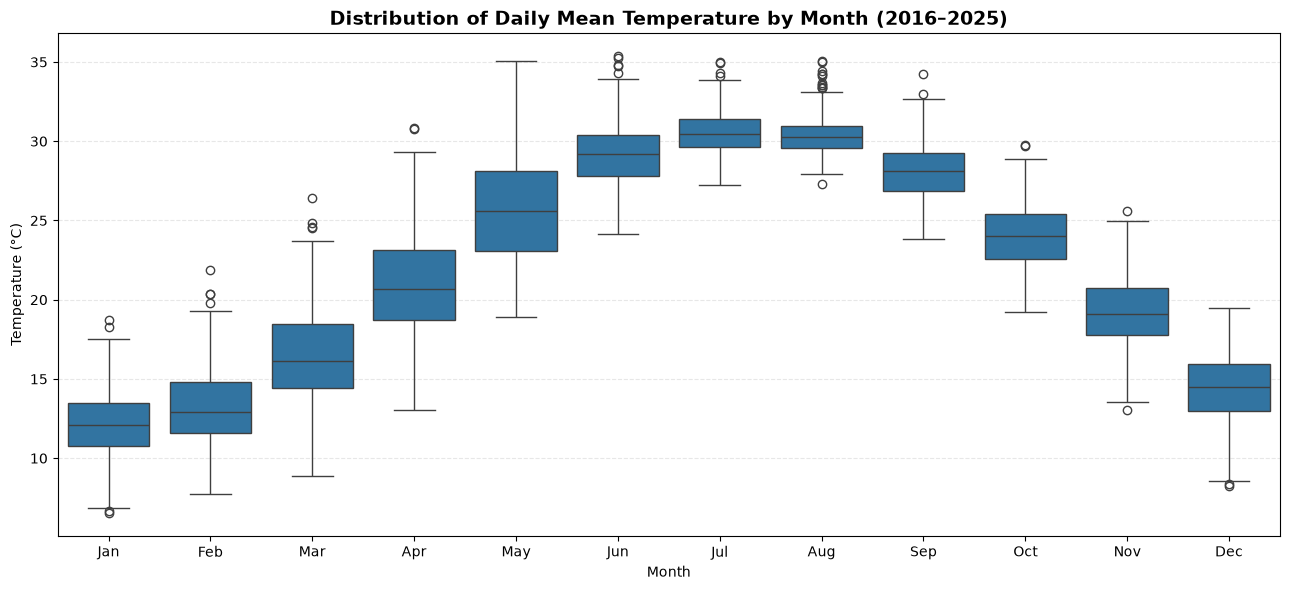

Interquartile Range of T2M by Month (°C):
Jan    2.74
Feb    3.22
Mar    4.05
Apr    4.44
May    5.10
Jun    2.61
Jul    1.73
Aug    1.43
Sep    2.39
Oct    2.82
Nov    2.95
Dec    2.96

Month with the widest spread: May
Month with the narrowest spread: Aug


In [82]:
import seaborn as sns

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(13, 6))

sns.boxplot(
    data=weather_data_df,
    x=weather_data_df["date"].dt.month,
    y="T2M",
    ax=ax
)

ax.set_xticks(range(12))
ax.set_xticklabels(month_names)
ax.set_title(
    "Distribution of Daily Mean Temperature by Month (2016–2025)",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Spread of each month (IQR) to support the interpretation
monthly_iqr = (
    weather_data_df.groupby(weather_data_df["date"].dt.month)["T2M"]
    .quantile(0.75)
    - weather_data_df.groupby(weather_data_df["date"].dt.month)["T2M"]
    .quantile(0.25)
)
monthly_iqr.index = month_names

print("Interquartile Range of T2M by Month (°C):")
print(monthly_iqr.round(2).to_string())
print("\nMonth with the widest spread:", monthly_iqr.idxmax())
print("Month with the narrowest spread:", monthly_iqr.idxmin())

### Findings

* The interquartile range (IQR) of daily mean temperature was widest in May (5.10°C) and narrowest in August (1.43°C).
* The spring months show the largest spread: March (4.05°C), April (4.44°C), and May (5.10°C). These are the months of fastest warming, so daily temperatures inside the same month vary widely.
* The summer months show the most stable temperatures, with IQR values of 2.61°C in June, 1.73°C in July, and 1.43°C in August.
* The autumn and winter months have moderate spread, with IQR values between 2.39°C (September) and 3.22°C (February).
* The monthly average temperature rises from about 12°C in January to about 31°C in July and then falls again, which confirms the strong annual seasonality.
* Part of the spread in spring months comes from the seasonal warming trend inside the month itself, not only from random day-to-day variation.

**Conclusion:** Temperature variability is not constant across the year. It is highest in spring and lowest in summer, which is

## 14. Monthly Precipitation Patterns

Analyze precipitation patterns in Cairo from 2016 to 2025 using daily precipitation data.

The analysis will calculate average daily precipitation and average monthly accumulated precipitation for each calendar month to identify seasonal rainfall patterns and the wettest and driest months.

This analysis will help characterize rainfall variability and assess the availability of useful precipitation patterns for weather forecasting.


In [39]:
# Create a copy and extract calendar information
precipitation_df = weather_data_df[["date", "PRECTOTCORR"]].copy()

precipitation_df["year"] = precipitation_df["date"].dt.year
precipitation_df["month"] = precipitation_df["date"].dt.month

# Calculate average daily precipitation for each month
average_daily_precipitation = (
    precipitation_df.groupby("month")["PRECTOTCORR"].mean()
)

# Calculate monthly accumulated precipitation for each year
monthly_totals = (
    precipitation_df.groupby(["year", "month"])["PRECTOTCORR"].sum()
)

# Calculate average monthly total across all years
average_monthly_total = monthly_totals.groupby("month").mean()

# Combine the results
monthly_precipitation = pd.DataFrame({
    "Average Daily Precipitation (mm/day)": average_daily_precipitation,
    "Average Monthly Total (mm)": average_monthly_total
})

# Add month names
monthly_precipitation.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Display results
print("Monthly Precipitation Analysis (2016–2025):")
print(monthly_precipitation.round(3).to_string())

print("\nWettest Month Based on Average Monthly Total:")
print(monthly_precipitation["Average Monthly Total (mm)"].idxmax())

print("\nDriest Month Based on Average Monthly Total:")
print(monthly_precipitation["Average Monthly Total (mm)"].idxmin())

Monthly Precipitation Analysis (2016–2025):
     Average Daily Precipitation (mm/day)  Average Monthly Total (mm)
Jan                                 0.740                      22.948
Feb                                 0.406                      11.477
Mar                                 0.898                      27.840
Apr                                 0.529                      15.867
May                                 0.034                       1.050
Jun                                 0.036                       1.094
Jul                                 0.033                       1.008
Aug                                 0.011                       0.352
Sep                                 0.042                       1.266
Oct                                 0.422                      13.092
Nov                                 1.059                      31.764
Dec                                 0.459                      14.227

Wettest Month Based on Average Monthly Total:

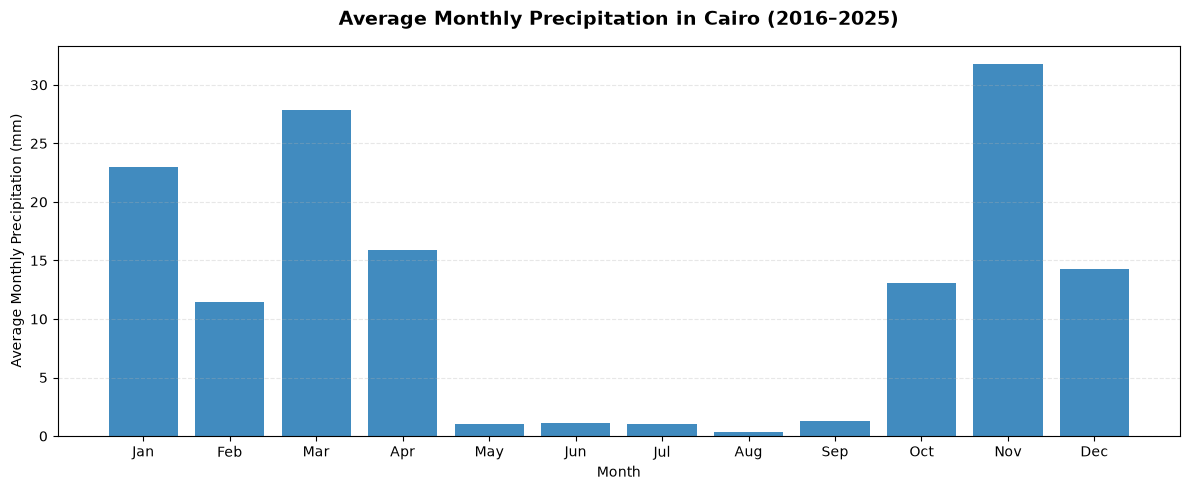

In [40]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    monthly_precipitation.index,
    monthly_precipitation["Average Monthly Total (mm)"],
    alpha=0.85
)

ax.set_title(
    "Average Monthly Precipitation in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Monthly Precipitation (mm)")

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* November had the highest average monthly accumulated precipitation, at 31.764 mm.
* August had the lowest average monthly accumulated precipitation, at 0.352 mm.
* Precipitation was generally higher during parts of autumn and winter than during summer.
* Summer months, particularly August, showed very low average precipitation.
* Monthly precipitation patterns indicate seasonality that differs from the seasonal temperature cycle.

**Conclusion:** Precipitation in Cairo exhibits a seasonal pattern, with higher average monthly totals in November and March and very low totals during summer.


## 15. 30-Day Rolling Average of Mean Temperature

Calculate a 30-day rolling average of daily mean temperature (`T2M`) to smooth short-term fluctuations and highlight broader temperature patterns over time.

The rolling average will be visualized alongside the original daily temperatures to make the underlying trend easier to observe.

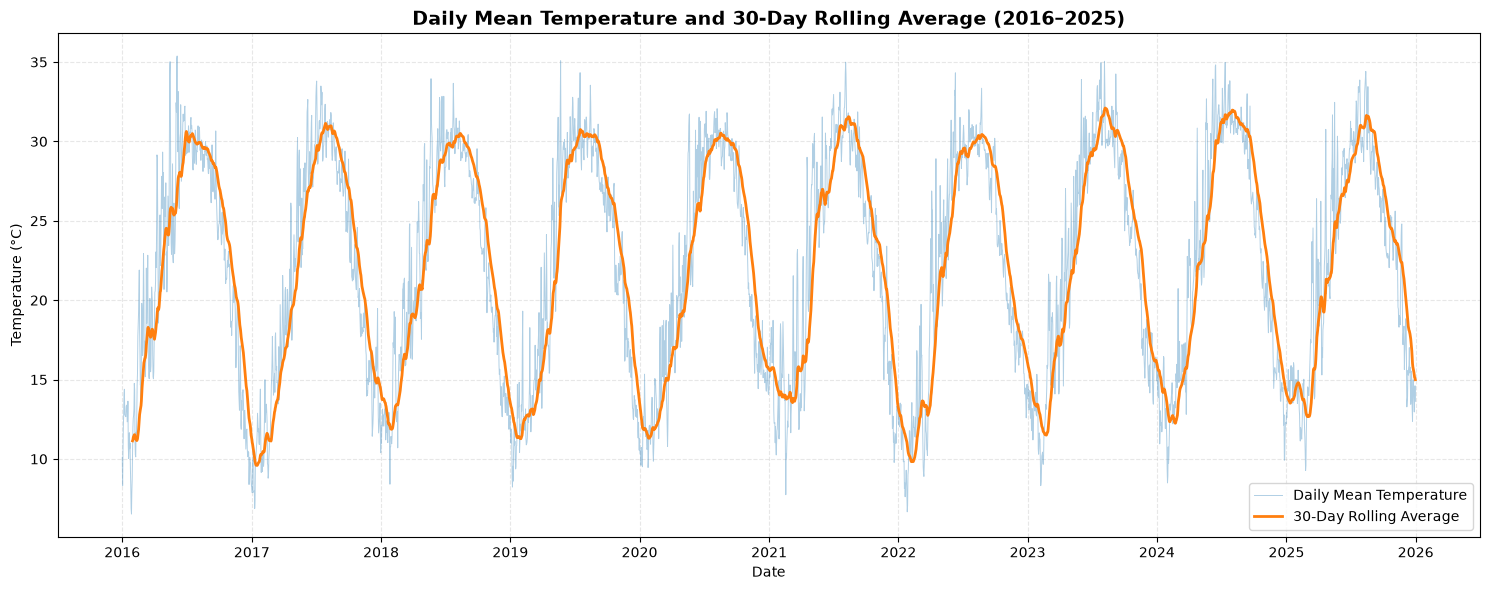

In [42]:
# Calculate the 30-day rolling average
weather_data_df["T2M_30D_ROLLING"] = (
    weather_data_df["T2M"].rolling(window=30).mean()
)

# Plot daily temperature and rolling average
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    weather_data_df["date"],
    weather_data_df["T2M"],
    label="Daily Mean Temperature",
    alpha=0.35,
    linewidth=0.7
)

ax.plot(
    weather_data_df["date"],
    weather_data_df["T2M_30D_ROLLING"],
    label="30-Day Rolling Average",
    linewidth=2
)

ax.set_title(
    "Daily Mean Temperature and 30-Day Rolling Average (2016–2025)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
print("30-Day Rolling Average Summary:")
print(
    weather_data_df["T2M_30D_ROLLING"]
    .describe()
    .round(2)
    .to_string()
)

print("\nLowest 30-Day Rolling Average:")
print(
    weather_data_df.loc[
        weather_data_df["T2M_30D_ROLLING"].idxmin(),
        ["date", "T2M_30D_ROLLING"]
    ].to_string()
)

print("\nHighest 30-Day Rolling Average:")
print(
    weather_data_df.loc[
        weather_data_df["T2M_30D_ROLLING"].idxmax(),
        ["date", "T2M_30D_ROLLING"]
    ].to_string()
)


30-Day Rolling Average Summary:
count    3624.00
mean       22.17
std         6.62
min         9.59
25%        15.91
50%        22.88
75%        28.74
max        32.10

Lowest 30-Day Rolling Average:
date               2017-01-16 00:00:00
T2M_30D_ROLLING               9.592667

Highest 30-Day Rolling Average:
date               2023-08-08 00:00:00
T2M_30D_ROLLING                 32.103


### Findings

- The 30-day rolling average contains 3,624 valid observations.
- The mean rolling temperature is approximately 22.17°C.
- The lowest 30-day rolling average was 9.59°C on January 16, 2017.
- The highest 30-day rolling average was 32.10°C on August 8, 2023.
- The rolling average smooths short-term daily fluctuations and helps reveal broader temperature patterns.
- The first 29 observations are missing because a complete 30-day window is required.

These results provide a clearer view of temperature variations over time, but they do not establish a long-term climate trend on their own.

## 15.1. Rolling Standard Deviation of Mean Temperature

Calculate the 7-day and 30-day rolling standard deviation of daily mean temperature (`T2M`) to visualize local volatility over time.

A higher rolling standard deviation means larger day-to-day temperature variation within that window.

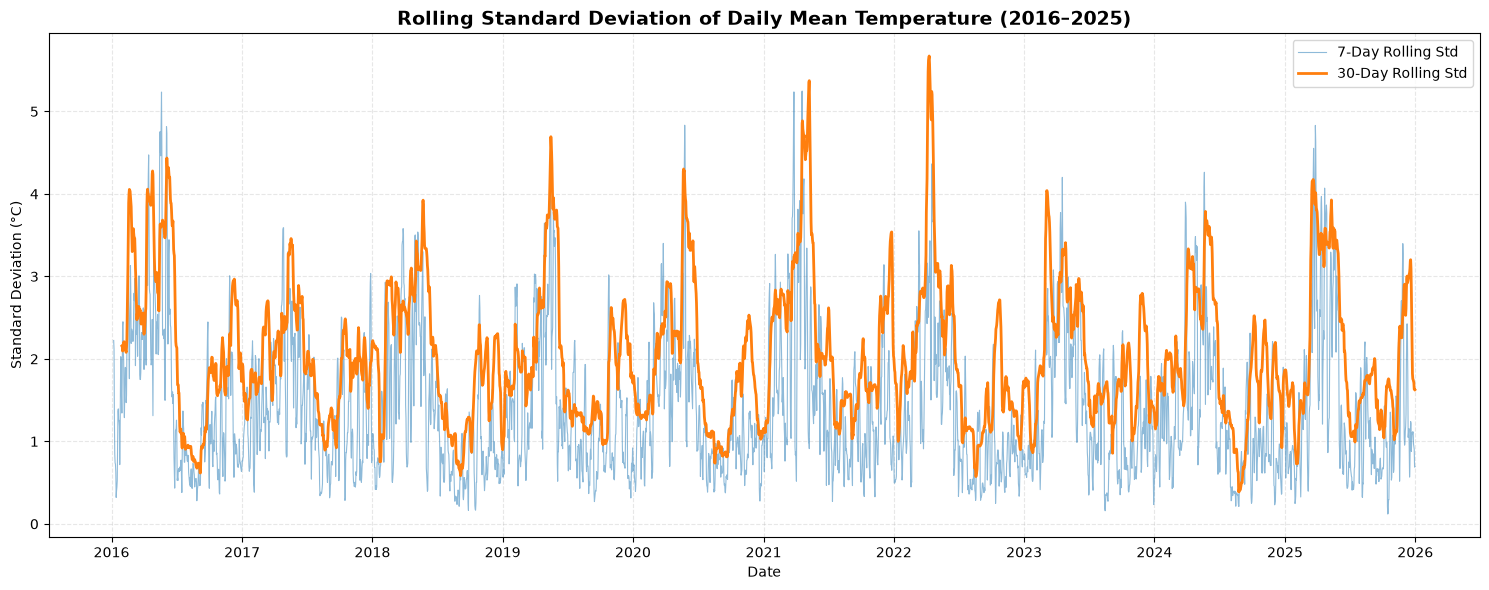

       T2M_7D_STD  T2M_30D_STD
count     3647.00      3624.00
mean         1.40         2.04
std          0.84         0.86
min          0.12         0.39
25%          0.77         1.40
50%          1.18         1.87
75%          1.88         2.56
max          5.25         5.67


In [81]:
weather_data_df["T2M_7D_STD"] = weather_data_df["T2M"].rolling(window=7).std()
weather_data_df["T2M_30D_STD"] = weather_data_df["T2M"].rolling(window=30).std()

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(weather_data_df["date"], weather_data_df["T2M_7D_STD"],
        label="7-Day Rolling Std", alpha=0.5, linewidth=0.8)
ax.plot(weather_data_df["date"], weather_data_df["T2M_30D_STD"],
        label="30-Day Rolling Std", linewidth=2)

ax.set_title("Rolling Standard Deviation of Daily Mean Temperature (2016–2025)",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Standard Deviation (°C)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

print(weather_data_df[["T2M_7D_STD", "T2M_30D_STD"]].describe().round(2).to_string())

### Findings

* The 30-day rolling standard deviation of daily mean temperature averaged approximately 2.04°C, ranging from 0.39°C to 5.67°C.
* The 7-day rolling standard deviation averaged approximately 1.40°C, with a maximum of 5.25°C. It is lower than the 30-day version because shorter windows capture less variation.
* Temperature variability is not constant over time. The rolling standard deviation changes across the year and follows a recurring pattern.
* The monthly average temperatures show the fastest warming between March and May and the fastest cooling between October and November. Windows covering these transition periods contain a larger temperature range, which is consistent with higher rolling standard deviation values.
* The summer months (July and August) have the most stable average temperatures, so windows in this period are expected to show lower variability.
* The 30-day rolling standard deviation is influenced by the seasonal temperature change inside each window, so high values partly reflect seasonal transitions and not only random day-to-day variability.

**Conclusion:** Local temperature volatility varies seasonally, which supports the strong seasonality identified in the monthly analysis and the STL decomposition. This variation in volatility should be considered when building a forecasting model.

## 16. Time-Series Decomposition Using STL

Apply Seasonal-Trend decomposition using Loess (STL) to the daily mean temperature (`T2M`) data collected from Cairo between 2016 and 2025.

The decomposition separates the time series into three components:

* **Trend:** The underlying long-term movement in temperature.
* **Seasonal:** The recurring annual temperature pattern.
* **Residual:** The remaining variations not explained by the trend and seasonal components.

A seasonal period of 365 days will be used to represent the approximate annual cycle in daily temperature data.


In [44]:
from statsmodels.tsa.seasonal import STL

In [45]:
# Prepare the daily mean temperature time series
temperature_series = (
    weather_data_df
    .set_index("date")["T2M"]
    .asfreq("D")
)

# Check for missing values
print("Missing values:", temperature_series.isna().sum())

# Apply STL decomposition
stl_model = STL(
    temperature_series,
    period=365,
    robust=True
)

stl_result = stl_model.fit()

print("STL decomposition completed successfully.")

Missing values: 0
STL decomposition completed successfully.


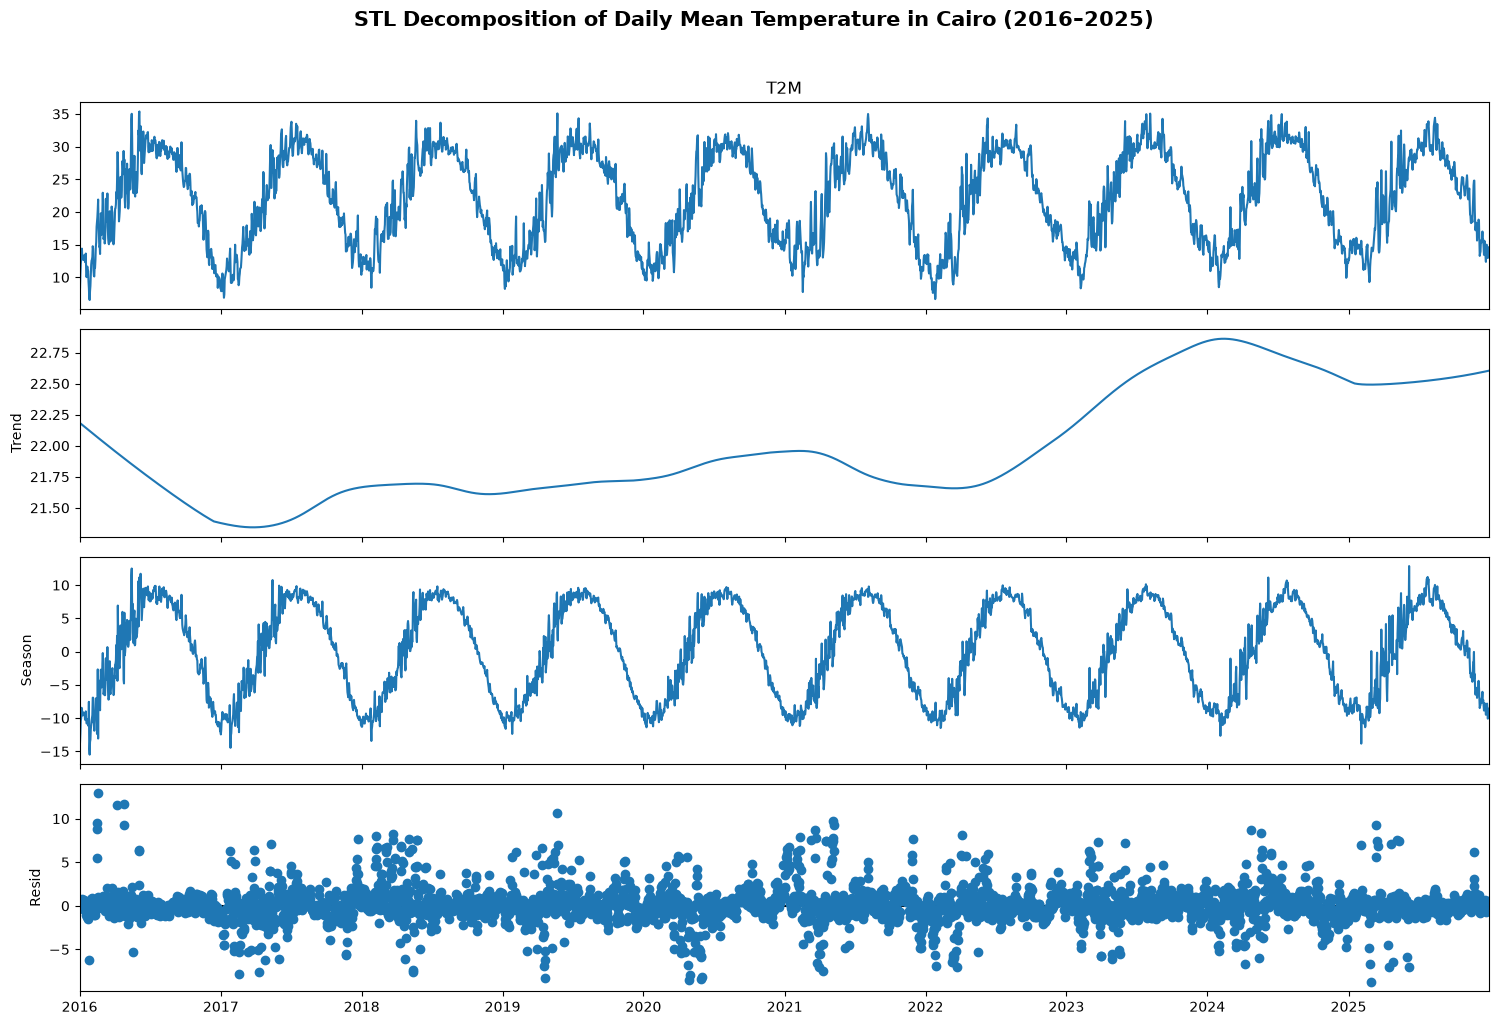

In [46]:
# Plot STL decomposition
fig = stl_result.plot()

fig.set_size_inches(15, 10)
fig.suptitle(
    "STL Decomposition of Daily Mean Temperature in Cairo (2016–2025)",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [47]:
stl_components = pd.DataFrame({
    "Trend": stl_result.trend,
    "Seasonal": stl_result.seasonal,
    "Residual": stl_result.resid
})

print("STL Components Summary:")
print(stl_components.describe().round(3).to_string())

print("\nAverage Seasonal Effect by Month:")

monthly_seasonal = (
    stl_components["Seasonal"]
    .groupby(stl_components.index.month)
    .mean()
)

monthly_seasonal.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(monthly_seasonal.round(2).to_string())

STL Components Summary:
          Trend  Seasonal  Residual
count  3653.000  3653.000  3653.000
mean     21.982     0.012     0.108
std       0.439     6.779     1.982
min      21.343   -15.487    -8.729
25%      21.670    -6.560    -0.742
50%      21.809     0.659    -0.006
75%      22.492     6.719     0.787
max      22.861    12.863    12.901

Average Seasonal Effect by Month:
Jan   -9.80
Feb   -8.94
Mar   -5.56
Apr   -0.74
May    3.34
Jun    7.07
Jul    8.55
Aug    8.29
Sep    5.99
Oct    1.96
Nov   -2.83
Dec   -7.67


### Findings

* STL decomposition successfully separated the daily mean temperature series into trend, seasonal, and residual components.
* The trend component has a mean of approximately 21.98°C and a standard deviation of 0.44°C.
* The seasonal component shows a clear annual temperature pattern, with negative seasonal effects during the colder months and positive effects during the warmer months.
* July has the highest average seasonal effect (+8.55°C), while January has the lowest (-9.80°C).
* The residual component has a mean of approximately 0.11°C and a standard deviation of 1.98°C.
* Some residual observations have relatively large magnitudes and may require further investigation.

These results demonstrate that temperature seasonality is an important characteristic of the dataset and should be considered when developing a forecasting model.


## 17. Autocorrelation Analysis (ACF)

Analyze the autocorrelation of daily mean temperature (`T2M`) to understand how strongly temperature observations are related to previous days.

The Autocorrelation Function (ACF) measures the correlation between a time series and its lagged values.

This analysis will help identify temporal dependencies and recurring patterns that may be useful when selecting a time-series forecasting approach.



In [48]:
from statsmodels.graphics.tsaplots import plot_acf

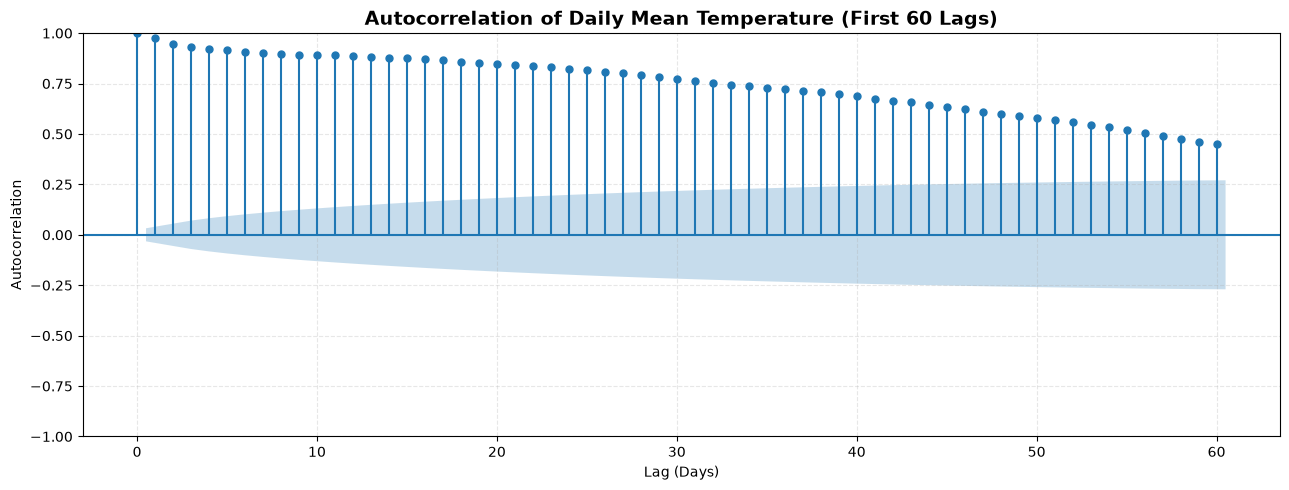

In [49]:
# Plot autocorrelation for daily mean temperature
fig, ax = plt.subplots(figsize=(13, 5))

plot_acf(
    weather_data_df["T2M"],
    lags=60,
    ax=ax,
    alpha=0.05
)

ax.set_title(
    "Autocorrelation of Daily Mean Temperature (First 60 Lags)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Autocorrelation")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [50]:
from statsmodels.tsa.stattools import acf

acf_values = acf(
    weather_data_df["T2M"],
    nlags=60,
    fft=True
)

selected_lags = [1, 2, 3, 7, 14, 30, 60]

print("Autocorrelation at Selected Lags:")

for lag in selected_lags:
    print(f"Lag {lag:2d}: {acf_values[lag]:.4f}")

Autocorrelation at Selected Lags:
Lag  1: 0.9767
Lag  2: 0.9480
Lag  3: 0.9301
Lag  7: 0.9025
Lag 14: 0.8778
Lag 30: 0.7717
Lag 60: 0.4508


### Findings

* Daily mean temperature shows strong positive autocorrelation at short lags.
* The lag-1 autocorrelation is 0.9767, indicating a strong relationship between consecutive daily temperature observations.
* Autocorrelation gradually decreases as the lag increases, reaching 0.7717 at lag 30 and 0.4508 at lag 60.
* These results indicate that daily temperature observations contain substantial temporal dependence.
* High autocorrelation may reflect both temperature persistence and underlying trend or seasonal patterns.

The findings suggest that temporal dependencies should be considered when designing a forecasting model. Model performance must still be evaluated on a chronological holdout period.


## 17.1. Partial Autocorrelation Analysis (PACF)

Analyze the partial autocorrelation of daily mean temperature (`T2M`) to identify the direct relationship between the series and its lagged observations after accounting for the effects of intermediate lags.

The Partial Autocorrelation Function (PACF) complements the ACF analysis and can help identify potentially useful lag features for future time-series forecasting.


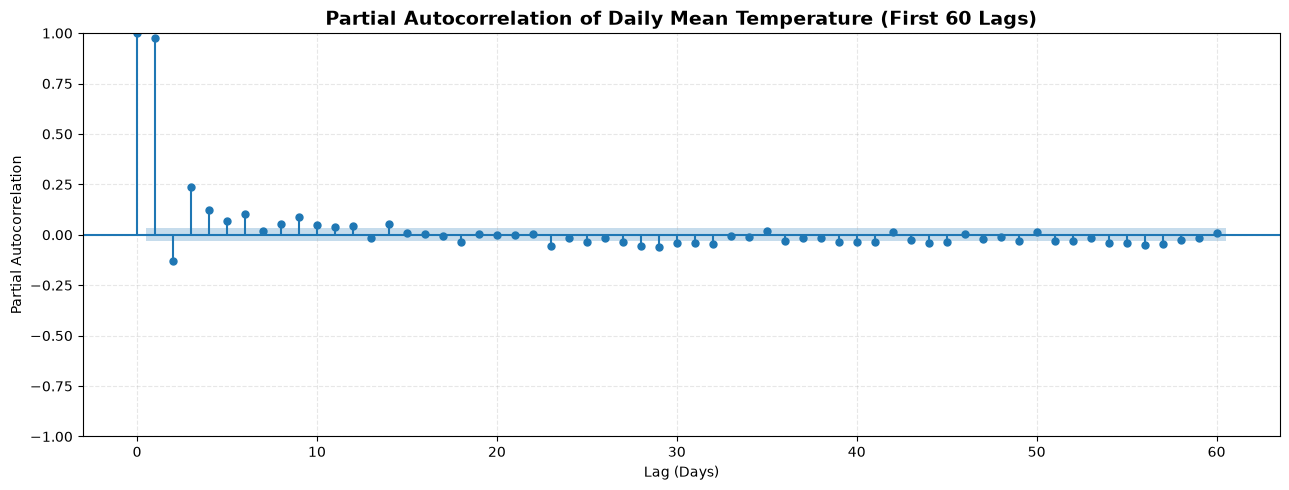

In [78]:
from statsmodels.graphics.tsaplots import plot_pacf

# Plot partial autocorrelation for daily mean temperature
fig, ax = plt.subplots(figsize=(13, 5))

plot_pacf(
    weather_data_df["T2M"],
    lags=60,
    ax=ax,
    alpha=0.05,
    method="ywm"
)

ax.set_title(
    "Partial Autocorrelation of Daily Mean Temperature (First 60 Lags)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Partial Autocorrelation")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [79]:
from statsmodels.tsa.stattools import pacf

pacf_values = pacf(
    weather_data_df["T2M"],
    nlags=60,
    method="ywm"
)

selected_lags = [1, 2, 3, 7, 14, 30, 60]

print("Partial Autocorrelation at Selected Lags:")

for lag in selected_lags:
    print(f"Lag {lag:2d}: {pacf_values[lag]:.4f}")

Partial Autocorrelation at Selected Lags:
Lag  1: 0.9767
Lag  2: -0.1284
Lag  3: 0.2365
Lag  7: 0.0207
Lag 14: 0.0516
Lag 30: -0.0388
Lag 60: 0.0083


### PACF Interpretation

The Partial Autocorrelation Function (PACF) reveals a strong positive partial autocorrelation at lag 1 (0.9767), indicating a strong direct relationship between daily mean temperature and its previous day's value after accounting for intermediate lags.

Lag 3 shows a weaker positive partial autocorrelation (0.2365), while the selected lags at 7, 14, 30, and 60 days exhibit relatively small values.

These results suggest that recent temperature observations, particularly the previous day's temperature, may provide useful features for future forecasting. However, statistical significance should be assessed using the PACF confidence intervals, and the usefulness of candidate lag features should ultimately be evaluated through time-aware model validation.


## 17.2. Long-Lag Autocorrelation Analysis (400 Lags)

The previous ACF plot covered only the first 60 lags, which is too short to reveal an annual cycle. This section extends the ACF to 400 lags so that the periodicity near lag 365 (one year) becomes visible.

If the series has stable annual seasonality, the autocorrelation should become strongly negative around half a year (about lag 182) and rise again to a clear positive peak near lag 365.

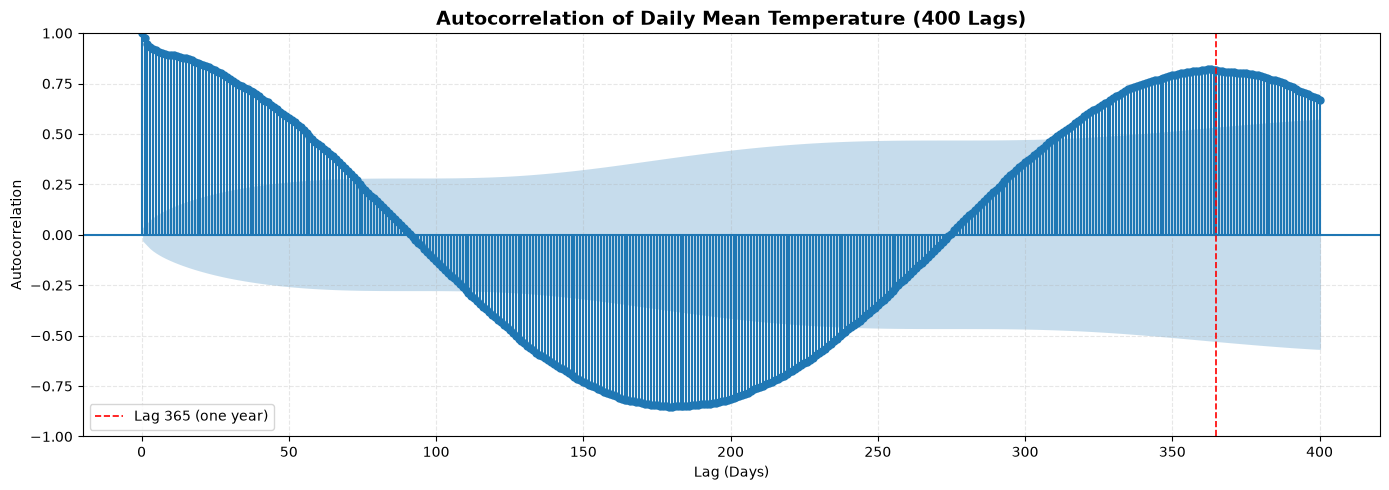

Autocorrelation at Selected Lags:
Lag  90: 0.0195
Lag 182: -0.8506
Lag 273: -0.0220
Lag 365: 0.8164

Lowest autocorrelation: lag 180 (-0.8520)
Highest autocorrelation between lag 300 and 400: lag 362 (0.8197)


In [85]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

# Plot ACF for 400 lags
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    weather_data_df["T2M"],
    lags=400,
    ax=ax,
    alpha=0.05
)

ax.axvline(365, color="red", linestyle="--", linewidth=1.2, label="Lag 365 (one year)")

ax.set_title(
    "Autocorrelation of Daily Mean Temperature (400 Lags)",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Lag (Days)")
ax.set_ylabel("Autocorrelation")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Numerical values at key lags
acf_long = acf(weather_data_df["T2M"], nlags=400, fft=True)

print("Autocorrelation at Selected Lags:")
for lag in [90, 182, 273, 365]:
    print(f"Lag {lag:3d}: {acf_long[lag]:.4f}")

# Lowest point (expected near half a year) and peak near one year
lowest_lag = acf_long[100:300].argmin() + 100
peak_lag = acf_long[300:400].argmax() + 300

print(f"\nLowest autocorrelation: lag {lowest_lag} ({acf_long[lowest_lag]:.4f})")
print(f"Highest autocorrelation between lag 300 and 400: lag {peak_lag} ({acf_long[peak_lag]:.4f})")

### Findings

* The autocorrelation at lag 365 (one year) is 0.8164, indicating that daily mean temperature is strongly related to the temperature one year prior.
* The autocorrelation reaches its lowest point at lag 180 (−0.8520), which is approximately half a year. This large negative value shows that conditions approximately six months apart are nearly opposite: when temperature is high, it is low half a year later.
* The autocorrelation oscillates around zero between the troughs and peaks, which reflects the seasonal cycle: lag 90 (∼3 months) has acf = 0.0195, and lag 273 (∼9 months) has acf = −0.0220.
* The strong positive autocorrelation at lag 365 and the near-peak at lag 362 (0.8197) confirm that the annual temperature cycle is highly regular and repeats nearly identically each year.
* This pattern is consistent with the STL decomposition, which showed a strong and stable seasonal component with a period of 365 days.

**Conclusion:** The autocorrelation function clearly reveals a 365-day annual cycle in daily mean temperature. The series exhibits the same temperature pattern each year, with strong positive autocorrelation at one-year separation and strong negative autocorrelation at half-year separation. This demonstrates that temperature seasonality is not random noise but a stable, repeating pattern.

## 18. Stationarity Testing Using the ADF Test

Apply the Augmented Dickey-Fuller (ADF) test to the daily mean temperature series (`T2M`) to assess whether the time series is stationary.

The test evaluates the null hypothesis that the series contains a unit root.

The results will help determine whether additional time-series transformations may be useful before forecasting.


In [51]:
from statsmodels.tsa.stattools import adfuller

# Apply the ADF test
adf_result = adfuller(weather_data_df["T2M"])

# Display the results
print("Augmented Dickey-Fuller (ADF) Test")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.6f}")
print(f"Number of Lags Used: {adf_result[2]}")
print(f"Number of Observations: {adf_result[3]}")

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value:.4f}")

# Interpret the p-value
if adf_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The test provides evidence that the series is stationary.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The test does not provide sufficient evidence that the series is stationary.")

Augmented Dickey-Fuller (ADF) Test
ADF Statistic: -4.2619
p-value: 0.000517
Number of Lags Used: 30
Number of Observations: 3622

Critical Values:
1%: -3.4322
5%: -2.8623
10%: -2.5672

Conclusion: Reject the null hypothesis.
The test provides evidence that the series is stationary.


C:\Users\moham\AppData\Local\Temp\ipykernel_8756\2157177581.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(weather_data_df["T2M"])


### Findings

* The ADF test returned a statistic of -4.2619 and a p-value of 0.000517.
* Since the p-value is below the 0.05 significance level, the null hypothesis of a unit root is rejected.
* The test provides statistical evidence against the presence of a unit root in the daily mean temperature series.
* This result does not imply that all seasonal patterns have been removed. The annual temperature seasonality identified during STL decomposition may still be present.
* Further analysis should consider both the stationarity characteristics and seasonal behavior of the series before selecting a forecasting model.


## 18.1. Confirming Stationarity with the KPSS Test

The ADF test and the KPSS test have opposite null hypotheses:

* **ADF:** the null hypothesis is that the series has a unit root (non-stationary).
* **KPSS:** the null hypothesis is that the series is stationary.

Applying both tests gives a more reliable conclusion. Both tests are applied to the original daily mean temperature (`T2M`) and to the STL residual component, which has the trend and seasonality removed.

In [84]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")

def run_stationarity_tests(series, name):
    series = series.dropna()

    adf_stat, adf_p = adfuller(series)[:2]
    kpss_stat, kpss_p = kpss(series, regression="c", nlags="auto")[:2]

    print(f"--- {name} ---")
    print(f"ADF  statistic: {adf_stat:.4f} | p-value: {adf_p:.6f}")
    print(f"KPSS statistic: {kpss_stat:.4f} | p-value: {kpss_p:.4f}")

    adf_stationary = adf_p < 0.05
    kpss_stationary = kpss_p >= 0.05

    if adf_stationary and kpss_stationary:
        verdict = "Both tests agree: stationary"
    elif not adf_stationary and not kpss_stationary:
        verdict = "Both tests agree: non-stationary"
    elif adf_stationary and not kpss_stationary:
        verdict = "Tests disagree: ADF says stationary, KPSS says non-stationary"
    else:
        verdict = "Tests disagree: ADF says non-stationary, KPSS says stationary"

    print(f"Conclusion: {verdict}\n")

run_stationarity_tests(weather_data_df["T2M"], "Original T2M series")
run_stationarity_tests(stl_result.resid, "STL residual component")

--- Original T2M series ---
ADF  statistic: -4.2619 | p-value: 0.000517
KPSS statistic: 0.0716 | p-value: 0.1000
Conclusion: Both tests agree: stationary

--- STL residual component ---
ADF  statistic: -9.7799 | p-value: 0.000000
KPSS statistic: 0.0805 | p-value: 0.1000
Conclusion: Both tests agree: stationary



### Findings

* For the original daily mean temperature (`T2M`), the ADF test (statistic = -4.2619, p = 0.0005) rejected the unit root hypothesis, and the KPSS test (statistic = 0.0716, p > 0.10) did not reject the null hypothesis of stationarity. Both tests agree that the series is stationary.
* For the STL residual component, the ADF test (statistic = -9.7799, p < 0.001) and the KPSS test (statistic = 0.0805, p > 0.10) also agree that the residuals are stationary.
* The KPSS p-value is reported as 0.10 because the statsmodels implementation truncates it at the edge of its lookup table. The true p-value is larger than 0.10.
* The ADF and KPSS tests check for a unit root and for a changing mean level. They do not check for seasonality. The strong annual seasonality identified in the STL decomposition is still present in the original series. It is stable and repeats each year, so the series is stationary around a regular seasonal pattern, not free of pattern.
* The STL trend component varies only slightly (standard deviation of about 0.44°C), which is consistent with the absence of a strong long-term drift.

**Conclusion:** The series is stationary according to both tests, so no differencing is required to remove a unit root. However, the stable annual seasonality must still be handled explicitly in forecasting, for example by using seasonal terms, seasonal differencing, or calendar features such as month and day of year.

## 19. Correlation Analysis of Weather Variables

Analyze the linear relationships between daily weather variables using a Pearson correlation matrix.

The analysis will examine the relationships between temperature, precipitation, wind speed, and relative humidity.

A correlation heatmap will be used to visualize the strength and direction of these relationships and identify potentially related variables for future weather forecasting.


In [53]:
weather_columns = [
    "T2M_MAX",
    "T2M_MIN",
    "T2M",
    "PRECTOTCORR",
    "WS10M",
    "RH2M"
]

correlation_matrix = weather_data_df[weather_columns].corr()

print("Correlation Matrix:")
print(correlation_matrix.round(3).to_string())

Correlation Matrix:
             T2M_MAX  T2M_MIN    T2M  PRECTOTCORR  WS10M   RH2M
T2M_MAX        1.000    0.942  0.988       -0.128  0.157 -0.753
T2M_MIN        0.942    1.000  0.978       -0.087  0.155 -0.637
T2M            0.988    0.978  1.000       -0.112  0.151 -0.719
PRECTOTCORR   -0.128   -0.087 -0.112        1.000  0.031  0.184
WS10M          0.157    0.155  0.151        0.031  1.000 -0.153
RH2M          -0.753   -0.637 -0.719        0.184 -0.153  1.000


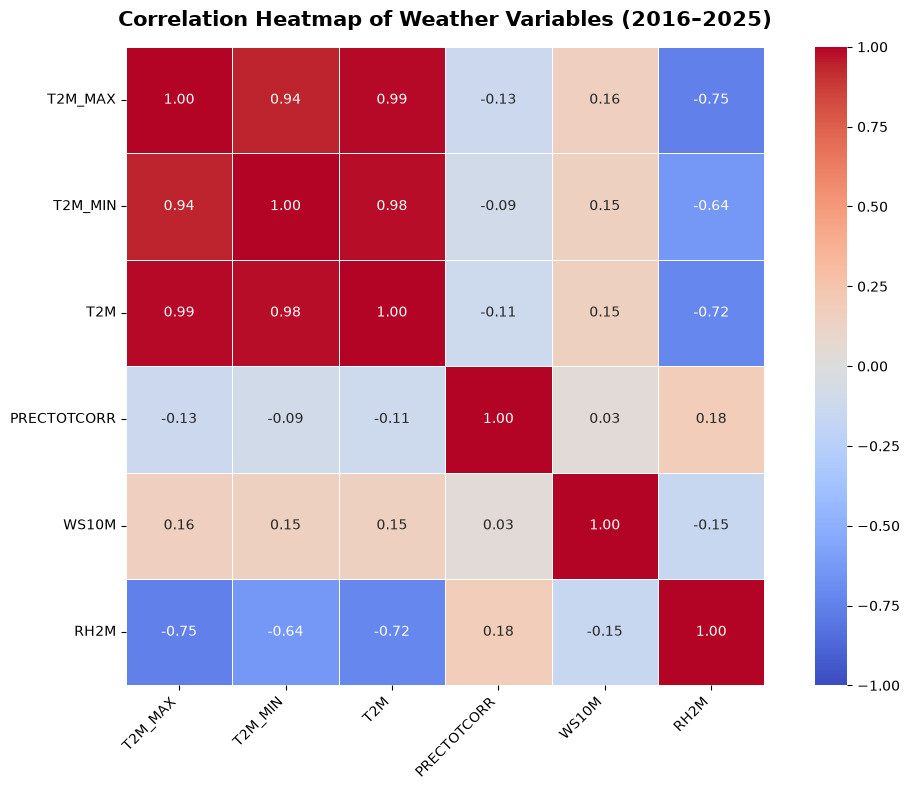

In [54]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)

plt.title(
    "Correlation Heatmap of Weather Variables (2016–2025)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### Findings

* `T2M_MAX` and `T2M` show a very strong positive correlation of 0.988.
* `T2M_MIN` and `T2M` also show a very strong positive correlation of 0.978.
* Relative humidity (`RH2M`) has a strong negative correlation with maximum temperature (-0.753) and mean temperature (-0.719).
* Precipitation (`PRECTOTCORR`) has weak linear correlations with the temperature variables.
* Wind speed (`WS10M`) shows weak linear correlations with the other weather variables in this dataset.
* The strong correlations among temperature variables indicate that these measurements share similar patterns.
* Correlation does not imply causation, and weak linear correlation does not rule out nonlinear relationships.

These findings provide an initial understanding of the relationships between weather variables and will help guide further exploratory analysis and forecasting feature selection.


## 20. Wind Speed Analysis

Analyze daily wind speed observations (`WS10M`) in Cairo from 2016 to 2025.

The analysis will examine the distribution of wind speed values and identify the highest recorded observations.

A histogram and a box plot will be used to understand the distribution, variability, and potential extreme values in wind speed.


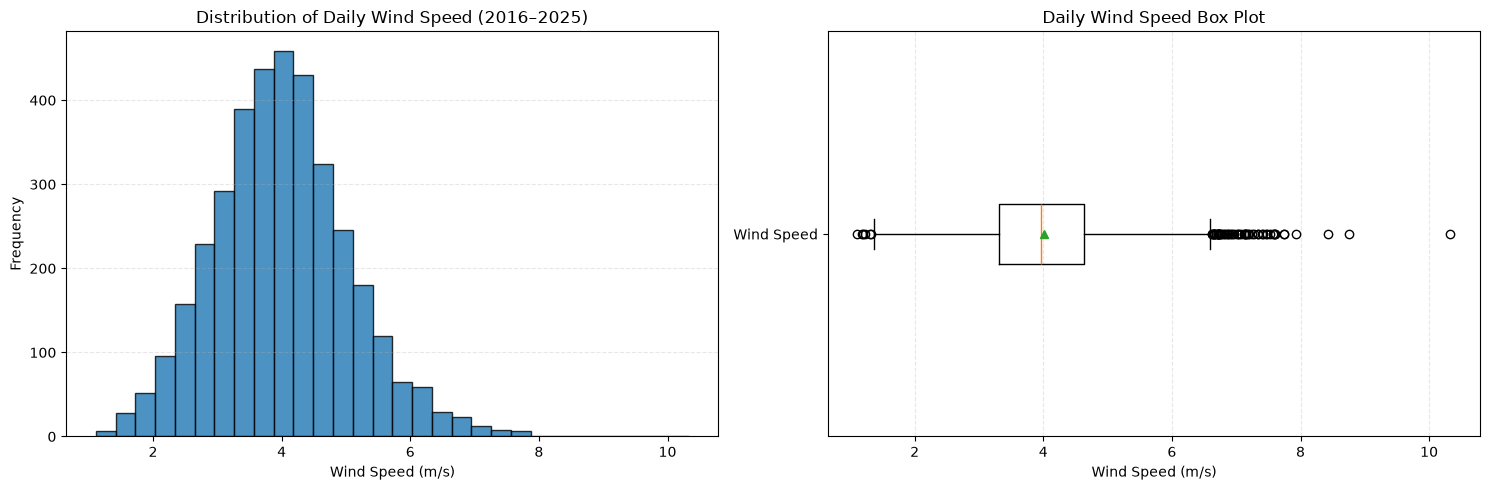

In [80]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(
    weather_data_df["WS10M"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Distribution of Daily Wind Speed (2016–2025)")
axes[0].set_xlabel("Wind Speed (m/s)")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Box plot
axes[1].boxplot(
    weather_data_df["WS10M"],
    orientation="horizontal",
    showmeans=True
)

axes[1].set_title("Daily Wind Speed Box Plot")
axes[1].set_xlabel("Wind Speed (m/s)")
axes[1].set_yticks([1])
axes[1].set_yticklabels(["Wind Speed"])
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:

# Calculate descriptive statistics
wind_stats = weather_data_df["WS10M"].describe()

print("Wind Speed Statistics (m/s):")
print(wind_stats.round(3).to_string())

# Identify the highest wind speed observations
print("\nHighest Wind Speed Observations:")
print(
    weather_data_df.nlargest(5, "WS10M")[["date", "WS10M"]]
    .to_string(index=False)
)

# Count potential outliers using the IQR method
Q1 = weather_data_df["WS10M"].quantile(0.25)
Q3 = weather_data_df["WS10M"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

wind_outliers = weather_data_df[
    weather_data_df["WS10M"] > upper_bound
]

print(f"\nQ1: {Q1:.3f} m/s")
print(f"Q3: {Q3:.3f} m/s")
print(f"IQR: {IQR:.3f} m/s")
print(f"Upper IQR Bound: {upper_bound:.3f} m/s")
print(f"Potential High Wind Outliers: {len(wind_outliers)}")


Wind Speed Statistics (m/s):
count    3653.000
mean        4.005
std         1.057
min         1.110
25%         3.310
50%         3.970
75%         4.630
max        10.330

Highest Wind Speed Observations:
      date  WS10M
2020-03-13  10.33
2019-01-16   8.76
2019-01-13   8.43
2019-03-30   7.93
2019-12-24   7.75

Q1: 3.310 m/s
Q3: 4.630 m/s
IQR: 1.320 m/s
Upper IQR Bound: 6.610 m/s
Potential High Wind Outliers: 57


### Findings

* The average daily wind speed was approximately 4.005 m/s, with a standard deviation of 1.057 m/s.
* The median wind speed was 3.970 m/s, indicating that the mean and median are relatively close.
* The maximum recorded wind speed was 10.33 m/s on March 13, 2020.
* The IQR method identified 57 observations above the upper bound of 6.61 m/s, representing approximately 1.56% of the dataset.
* These observations are potential high-value outliers, but they are not necessarily data errors.
* The identified observations should be retained unless further investigation provides evidence that they are invalid.

This analysis provides an overview of wind speed variability and highlights observations that may warrant further investigation.


## 21. Relative Humidity Analysis

Analyze daily relative humidity observations (`RH2M`) in Cairo from 2016 to 2025.

The analysis will examine the distribution and variability of relative humidity and identify potentially unusual observations.

A histogram and a box plot will be used to visualize the distribution and highlight potential extreme values.


C:\Users\moham\AppData\Local\Temp\ipykernel_8756\3816968748.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


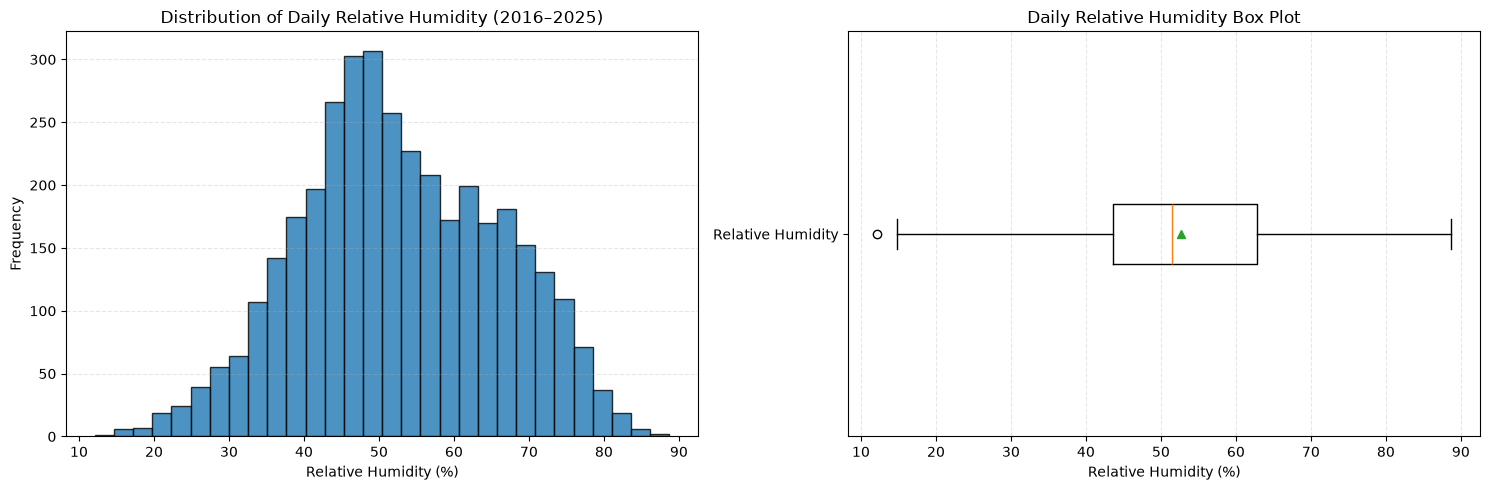

In [57]:
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(
    weather_data_df["RH2M"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Distribution of Daily Relative Humidity (2016–2025)")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Box plot
axes[1].boxplot(
    weather_data_df["RH2M"],
    vert=False,
    showmeans=True
)

axes[1].set_title("Daily Relative Humidity Box Plot")
axes[1].set_xlabel("Relative Humidity (%)")
axes[1].set_yticks([1])
axes[1].set_yticklabels(["Relative Humidity"])
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [58]:
# Calculate descriptive statistics
humidity_stats = weather_data_df["RH2M"].describe()

print("Relative Humidity Statistics (%):")
print(humidity_stats.round(3).to_string())

# Identify the highest and lowest humidity observations
print("\nHighest Relative Humidity Observations:")
print(
    weather_data_df.nlargest(5, "RH2M")[["date", "RH2M"]]
    .to_string(index=False)
)

print("\nLowest Relative Humidity Observations:")
print(
    weather_data_df.nsmallest(5, "RH2M")[["date", "RH2M"]]
    .to_string(index=False)
)

# Detect potential outliers using the IQR method
Q1 = weather_data_df["RH2M"].quantile(0.25)
Q3 = weather_data_df["RH2M"].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

humidity_outliers = weather_data_df[
    (weather_data_df["RH2M"] < lower_bound) |
    (weather_data_df["RH2M"] > upper_bound)
]

print(f"\nQ1: {Q1:.3f}%")
print(f"Q3: {Q3:.3f}%")
print(f"IQR: {IQR:.3f}%")
print(f"Lower IQR Bound: {lower_bound:.3f}%")
print(f"Upper IQR Bound: {upper_bound:.3f}%")
print(f"Potential Outliers: {len(humidity_outliers)}")


Relative Humidity Statistics (%):
count    3653.000
mean       52.686
std        13.257
min        12.120
25%        43.590
50%        51.520
75%        62.840
max        88.720

Highest Relative Humidity Observations:
      date  RH2M
2017-11-18 88.72
2020-03-12 88.51
2021-12-23 85.76
2018-02-12 85.24
2023-12-13 84.60

Lowest Relative Humidity Observations:
      date  RH2M
2019-05-23 12.12
2019-05-22 14.79
2016-06-03 15.35
2025-04-22 15.88
2018-05-22 16.35

Q1: 43.590%
Q3: 62.840%
IQR: 19.250%
Lower IQR Bound: 14.715%
Upper IQR Bound: 91.715%
Potential Outliers: 1


### Findings

* The average daily relative humidity was approximately 52.69%, while the median was 51.52%.
* Relative humidity ranged from 12.12% to 88.72% during the study period.
* The lowest observation occurred on May 23, 2019, while the highest occurred on November 18, 2017.
* The IQR method identified one potential outlier below the lower bound of 14.715%.
* The identified observation should be investigated but should not be removed without evidence that it is invalid.
* The maximum observed relative humidity remained below the upper IQR bound of 91.715%.

This analysis summarizes the distribution and variability of relative humidity and identifies one observation for potential further investigation.


## 22. Precipitation Occurrence Analysis

Analyze the occurrence of precipitation (`PRECTOTCORR`) in Cairo from 2016 to 2025.

The analysis will distinguish between days with zero precipitation and days with positive precipitation values.

It will calculate the number and percentage of dry and rainy days and examine the distribution of precipitation on days with recorded rainfall.


In [59]:

# Count dry and rainy days
total_days = len(weather_data_df)

rainy_days = (weather_data_df["PRECTOTCORR"] > 0).sum()
dry_days = (weather_data_df["PRECTOTCORR"] == 0).sum()

# Calculate percentages
rainy_percentage = (rainy_days / total_days) * 100
dry_percentage = (dry_days / total_days) * 100

# Calculate precipitation statistics for rainy days only
rainy_precipitation = weather_data_df.loc[
    weather_data_df["PRECTOTCORR"] > 0,
    "PRECTOTCORR"
]

print("Precipitation Occurrence Analysis (2016–2025)")
print(f"Total Days: {total_days}")
print(f"Dry Days: {dry_days} ({dry_percentage:.2f}%)")
print(f"Rainy Days: {rainy_days} ({rainy_percentage:.2f}%)")

print("\nPrecipitation on Rainy Days (mm/day):")
print(rainy_precipitation.describe().round(3).to_string())



Precipitation Occurrence Analysis (2016–2025)
Total Days: 3653
Dry Days: 2724 (74.57%)
Rainy Days: 929 (25.43%)

Precipitation on Rainy Days (mm/day):
count    929.000
mean       1.528
std        5.676
min        0.010
25%        0.030
50%        0.120
75%        0.570
max       95.480


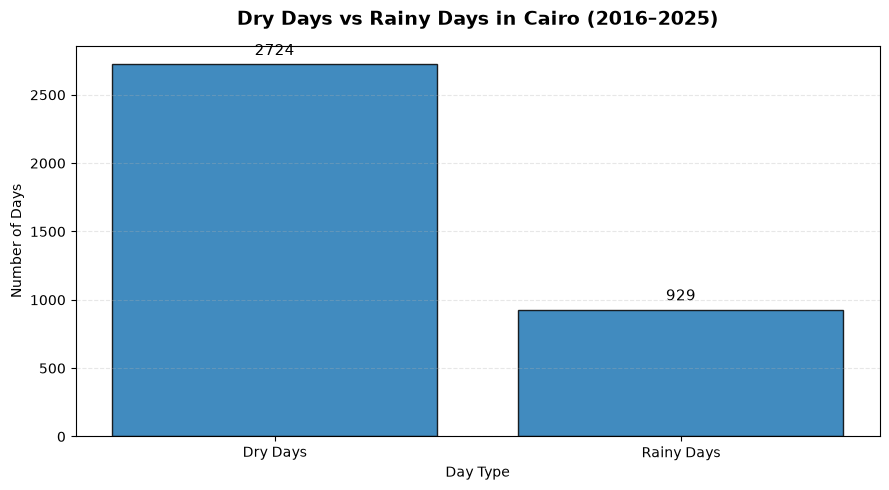

In [60]:

# Prepare the data
precipitation_counts = pd.Series({
    "Dry Days": dry_days,
    "Rainy Days": rainy_days
})

# Create the bar chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    precipitation_counts.index,
    precipitation_counts.values,
    edgecolor="black",
    alpha=0.85
)

# Display counts above the bars
ax.bar_label(bars, fmt="%d", padding=4, fontsize=11)

ax.set_title(
    "Dry Days vs Rainy Days in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Day Type")
ax.set_ylabel("Number of Days")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()



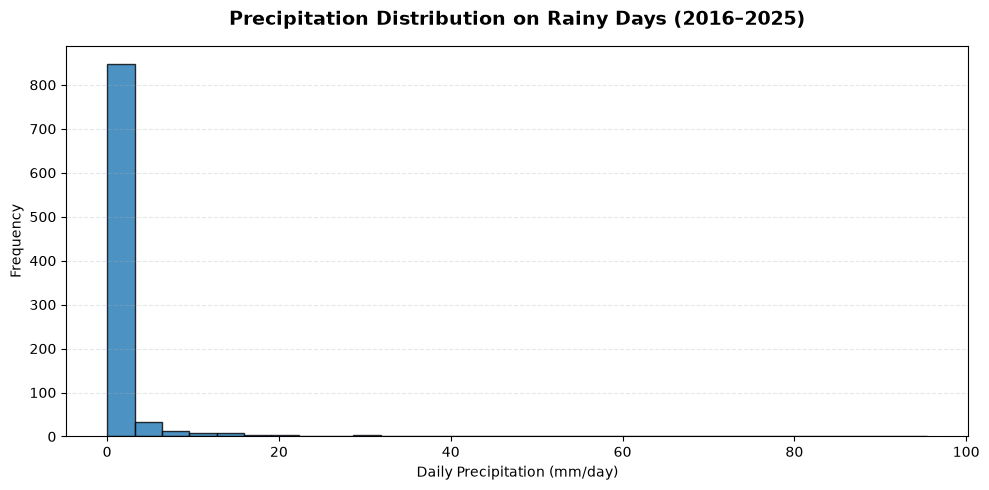

In [61]:
# Select days with positive precipitation
rainy_precipitation = weather_data_df.loc[
    weather_data_df["PRECTOTCORR"] > 0,
    "PRECTOTCORR"
]

# Create the histogram
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    rainy_precipitation,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

ax.set_title(
    "Precipitation Distribution on Rainy Days (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Daily Precipitation (mm/day)")
ax.set_ylabel("Frequency")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### Findings

* The dataset contains 3,653 daily observations from 2016 to 2025.
* Dry days account for 74.57% of the observations (2,724 days), while rainy days account for 25.43% (929 days).
* On rainy days, the average daily precipitation is 1.528 mm, while the median is only 0.120 mm.
* The mean being substantially higher than the median suggests a right-skewed precipitation distribution, where most rainy days have relatively low precipitation and a smaller number of days have much higher values.
* The maximum recorded daily precipitation is 95.48 mm/day. This value should be investigated as a potentially extreme observation, but it should not be removed without evidence that it is invalid.
* These findings show that precipitation has many zero-value days and a highly uneven distribution. Both characteristics should be considered when preparing the data for weather forecasting.


## 23. Monthly Rainy-Day Frequency

Analyze the frequency of rainy days in Cairo from 2016 to 2025 to identify seasonal patterns in precipitation occurrence.

A rainy day is defined as a day with precipitation greater than 0 mm/day.

The analysis will calculate the average number of rainy days per calendar month across the ten-year period and visualize the results using a bar chart.

This analysis will help identify the months in which rainfall occurs most and least frequently, complementing the previous analysis of precipitation amounts.


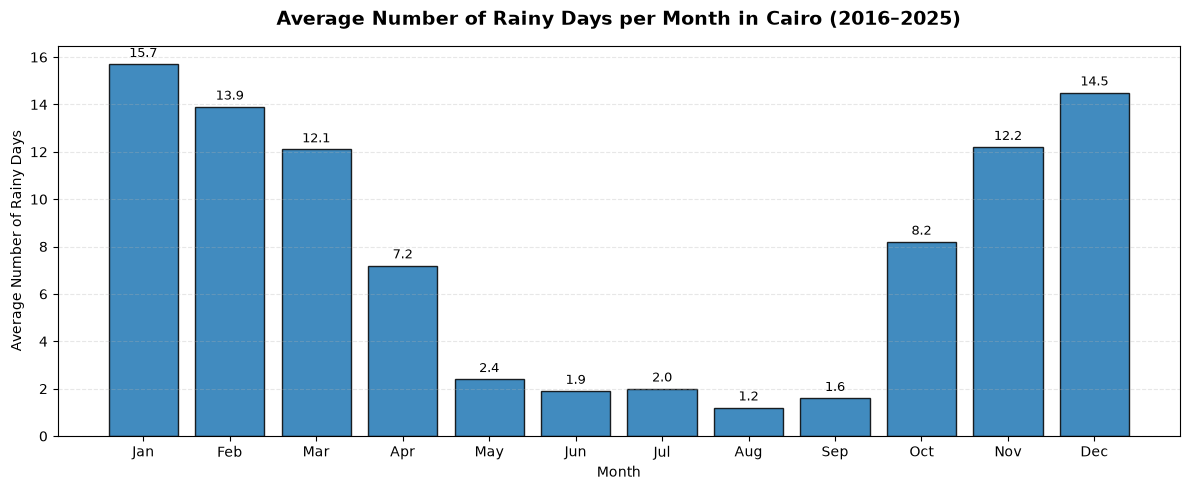

In [62]:
# Extract year and month
weather_data_df["year"] = weather_data_df["date"].dt.year
weather_data_df["month"] = weather_data_df["date"].dt.month

# Identify rainy days
weather_data_df["is_rainy_day"] = (
    weather_data_df["PRECTOTCORR"] > 0
)

# Count rainy days for each month of each year
monthly_rainy_days = (
    weather_data_df
    .groupby(["year", "month"])["is_rainy_day"]
    .sum()
    .reset_index(name="rainy_days")
)

# Calculate the average rainy days for each calendar month
average_rainy_days = (
    monthly_rainy_days
    .groupby("month")["rainy_days"]
    .mean()
    .reindex(range(1, 13))
)

# Replace month numbers with month names
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

average_rainy_days.index = month_names

# Visualize the results
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    average_rainy_days.index,
    average_rainy_days.values,
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=3,
    fontsize=9
)

ax.set_title(
    "Average Number of Rainy Days per Month in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Number of Rainy Days")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
print("Average Rainy Days per Month (2016–2025):")
print(average_rainy_days.round(2).to_string())

print("\nMonth with the Most Rainy Days:")
print(average_rainy_days.idxmax(), "-", round(average_rainy_days.max(), 2), "days")

print("\nMonth with the Fewest Rainy Days:")
print(average_rainy_days.idxmin(), "-", round(average_rainy_days.min(), 2), "days")

Average Rainy Days per Month (2016–2025):
Jan    15.7
Feb    13.9
Mar    12.1
Apr     7.2
May     2.4
Jun     1.9
Jul     2.0
Aug     1.2
Sep     1.6
Oct     8.2
Nov    12.2
Dec    14.5

Month with the Most Rainy Days:
Jan - 15.7 days

Month with the Fewest Rainy Days:
Aug - 1.2 days


### Findings

* January has the highest average number of rainy days, with approximately 15.7 days per month across the 2016–2025 period.
* August has the lowest average, with approximately 1.2 rainy days per month.
* Rainy-day frequency generally decreases from winter to summer, reaching its lowest levels during July and August.
* Rainfall occurrence increases again during autumn, with October averaging 8.2 rainy days and November averaging 12.2 rainy days per month.
* December and January show relatively frequent rainfall compared with the summer months.
* These results reveal a clear seasonal pattern in precipitation occurrence in Cairo. However, rainy-day frequency measures how often precipitation occurs, not how much rain falls. Both frequency and precipitation amounts may be useful for future forecasting.


## 23.1. Wet Day Analysis Using a 1 mm Threshold

The previous analysis defined a rainy day as any day with precipitation greater than 0 mm/day. NASA POWER is a satellite and reanalysis-based dataset, so it contains many very small precipitation values (for example 0.01 mm) that are unlikely to represent real rainfall events.

In this section, a wet day is redefined as a day with precipitation of at least 1 mm/day, which is a commonly used meteorological threshold. The results are compared with the previous definition.

Comparison of Definitions (2016-2025):
Rainy days (> 0 mm):  929 (25.43%)
Wet days (>= 1 mm):   176 (4.82%)

Average Wet Days per Month (>= 1 mm):
Jan    3.4
Feb    2.4
Mar    2.9
Apr    1.4
May    0.3
Jun    0.3
Jul    0.4
Aug    0.1
Sep    0.6
Oct    1.8
Nov    2.0
Dec    2.0


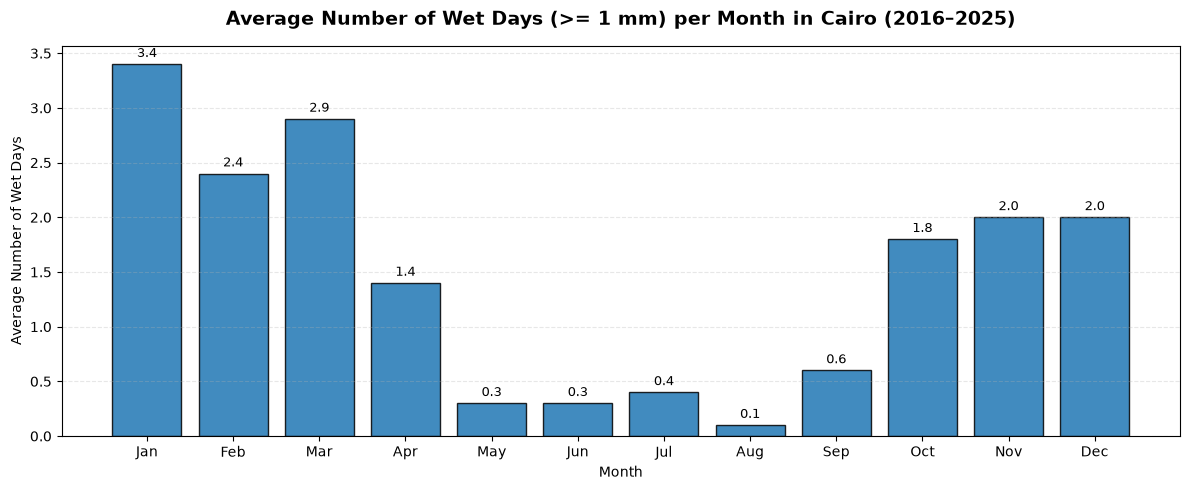


Wet Days per Year (>= 1 mm):
year
2016    24
2017    13
2018    16
2019    15
2020    21
2021    25
2022    19
2023    24
2024     8
2025    11


In [83]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Define wet days using a 1 mm threshold
weather_data_df["is_wet_day_1mm"] = weather_data_df["PRECTOTCORR"] >= 1

total_days = len(weather_data_df)
old_rainy = weather_data_df["is_rainy_day"].sum()
new_wet = weather_data_df["is_wet_day_1mm"].sum()

print("Comparison of Definitions (2016-2025):")
print(f"Rainy days (> 0 mm):  {old_rainy} ({old_rainy / total_days * 100:.2f}%)")
print(f"Wet days (>= 1 mm):   {new_wet} ({new_wet / total_days * 100:.2f}%)")

# Average number of wet days per calendar month
monthly_wet_days = (
    weather_data_df
    .groupby(["year", "month"])["is_wet_day_1mm"]
    .sum()
    .groupby("month")
    .mean()
)
monthly_wet_days.index = month_names

print("\nAverage Wet Days per Month (>= 1 mm):")
print(monthly_wet_days.round(2).to_string())

# Visualization
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    monthly_wet_days.index,
    monthly_wet_days.values,
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)

ax.set_title(
    "Average Number of Wet Days (>= 1 mm) per Month in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Month")
ax.set_ylabel("Average Number of Wet Days")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Annual total of wet days
annual_wet_days = weather_data_df.groupby("year")["is_wet_day_1mm"].sum()
print("\nWet Days per Year (>= 1 mm):")
print(annual_wet_days.to_string())

Wet Days per Year (>= 1 mm):
year
2016    24
2017    13
2018    16
2019    15
2020    21
2021    25
2022    19
2023    24
2024     8
2025    11

## 24. Annual Precipitation Analysis

Analyze annual precipitation totals in Cairo from 2016 to 2025 to understand year-to-year variations in rainfall.

The total precipitation for each year will be calculated by summing the daily precipitation observations.

A bar chart will be used to compare annual precipitation totals and identify the wettest and driest years in the dataset.

This analysis will help assess interannual rainfall variability and determine whether precipitation amounts differ substantially between years.


Annual Precipitation Totals (mm):
year
2016    284.64
2017    127.89
2018    101.64
2019     68.48
2020    209.10
2021    162.22
2022    123.52
2023    186.83
2024     95.10
2025     60.43

Wettest Year:
2016 - 284.64 mm

Driest Year:
2025 - 60.43 mm


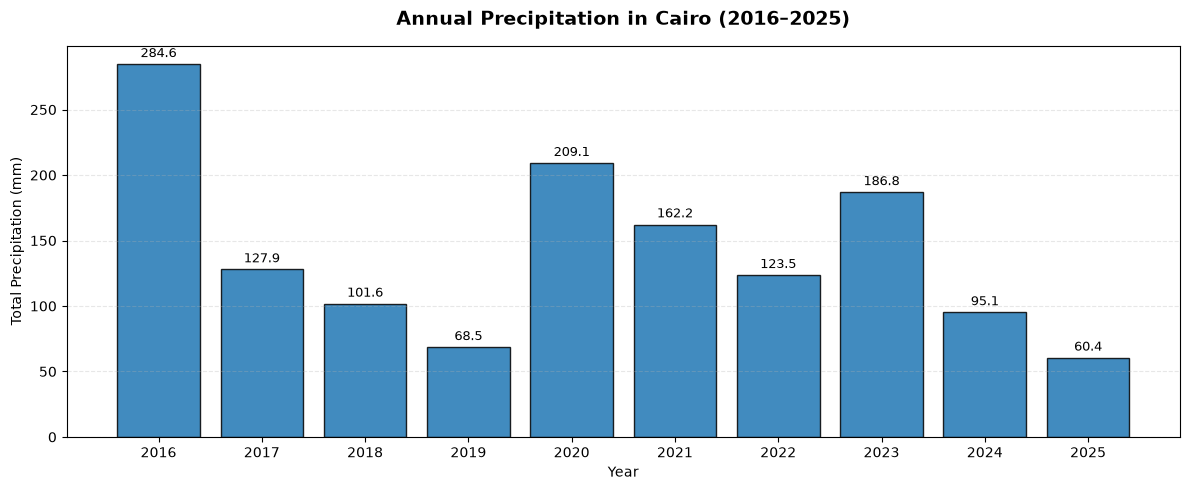

In [64]:
# Calculate total annual precipitation
annual_precipitation = (
    weather_data_df
    .groupby("year")["PRECTOTCORR"]
    .sum()
)

# Display annual totals
print("Annual Precipitation Totals (mm):")
print(annual_precipitation.round(2).to_string())

# Identify the wettest and driest years
print("\nWettest Year:")
print(
    annual_precipitation.idxmax(),
    "-",
    round(annual_precipitation.max(), 2),
    "mm"
)

print("\nDriest Year:")
print(
    annual_precipitation.idxmin(),
    "-",
    round(annual_precipitation.min(), 2),
    "mm"
)

# Visualize annual precipitation
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    annual_precipitation.index.astype(str),
    annual_precipitation.values,
    edgecolor="black",
    alpha=0.85
)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=3,
    fontsize=9
)

ax.set_title(
    "Annual Precipitation in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Total Precipitation (mm)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* Annual precipitation varied considerably across the 2016–2025 period.
* **2016 was the wettest year**, with a total recorded precipitation of 284.64 mm.
* **2025 was the driest year**, with a total recorded precipitation of 60.43 mm.
* Annual precipitation decreased from 284.64 mm in 2016 to 68.48 mm in 2019, then increased to 209.10 mm in 2020.
* After 2020, annual precipitation fluctuated, reaching 186.83 mm in 2023 before declining to 60.43 mm in 2025.
* These results indicate substantial year-to-year variability in precipitation. However, the ten-year period alone is not sufficient to establish a long-term climate trend.


## 25. Yearly Temperature Comparison

Analyze annual average temperatures in Cairo from 2016 to 2025 to examine year-to-year temperature variations.

The annual averages of daily maximum temperature (`T2M_MAX`), daily minimum temperature (`T2M_MIN`), and daily mean temperature (`T2M`) will be calculated.

A line chart will be used to compare the three temperature measurements across the ten-year period.

This analysis will help identify warmer and cooler years and provide an overview of annual temperature variability.


Annual Average Temperatures (°C):
      T2M_MAX  T2M_MIN    T2M
year                         
2016    29.96    15.13  21.99
2017    29.12    14.60  21.31
2018    30.04    15.65  22.33
2019    29.81    15.07  21.92
2020    29.57    14.97  21.74
2021    30.32    15.28  22.24
2022    29.43    14.86  21.67
2023    30.48    15.98  22.67
2024    30.47    15.76  22.60
2025    30.53    15.56  22.54

Warmest Year (based on T2M):
2023 - 22.67 °C

Coolest Year (based on T2M):
2017 - 21.31 °C


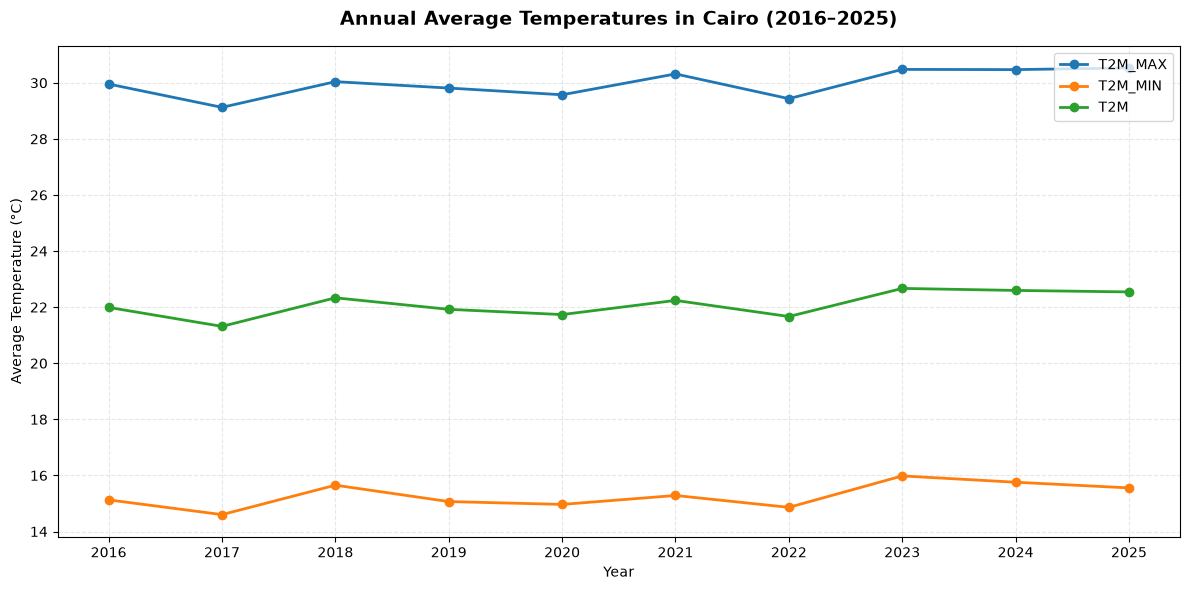

In [65]:
# Calculate annual average temperatures
annual_temperature = (
    weather_data_df
    .groupby("year")[["T2M_MAX", "T2M_MIN", "T2M"]]
    .mean()
)

# Display the results
print("Annual Average Temperatures (°C):")
print(annual_temperature.round(2).to_string())

# Identify the warmest and coolest years by mean temperature
print("\nWarmest Year (based on T2M):")
print(
    annual_temperature["T2M"].idxmax(),
    "-",
    round(annual_temperature["T2M"].max(), 2),
    "°C"
)

print("\nCoolest Year (based on T2M):")
print(
    annual_temperature["T2M"].idxmin(),
    "-",
    round(annual_temperature["T2M"].min(), 2),
    "°C"
)

# Visualize annual temperature averages
fig, ax = plt.subplots(figsize=(12, 6))

for column in ["T2M_MAX", "T2M_MIN", "T2M"]:
    ax.plot(
        annual_temperature.index,
        annual_temperature[column],
        marker="o",
        linewidth=2,
        label=column
    )

ax.set_title(
    "Annual Average Temperatures in Cairo (2016–2025)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Average Temperature (°C)")
ax.set_xticks(annual_temperature.index)
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* Annual average temperatures varied across the 2016–2025 period.
* **2023 was the warmest year** based on daily mean temperature (`T2M`), with an annual average of 22.67°C.
* **2017 was the coolest year**, with an annual average of 21.31°C.
* The annual average daily maximum temperature (`T2M_MAX`) ranged from 29.12°C in 2017 to 30.53°C in 2025.
* The annual average daily minimum temperature (`T2M_MIN`) ranged from 14.60°C in 2017 to 15.98°C in 2023.
* Mean temperatures increased between 2022 and 2023, then remained relatively similar in 2024 and 2025.
* These results show year-to-year temperature variability. However, ten years of observations are not sufficient on their own to establish a long-term climate trend.


## 26. Temperature Range Analysis

Analyze the daily temperature range in Cairo from 2016 to 2025.

The daily temperature range is calculated as the difference between daily maximum temperature (`T2M_MAX`) and daily minimum temperature (`T2M_MIN`).

The analysis will examine the distribution and variability of daily temperature ranges using descriptive statistics, a histogram, and a box plot.

This analysis helps characterize the difference between daytime and nighttime temperatures and identify potentially unusual observations.


In [66]:
# Calculate the daily temperature range
weather_data_df["TEMP_RANGE"] = (
    weather_data_df["T2M_MAX"] - weather_data_df["T2M_MIN"]
)

# Display descriptive statistics
print("Daily Temperature Range Statistics (°C):")
print(weather_data_df["TEMP_RANGE"].describe().round(2).to_string())

# Display the days with the largest temperature ranges
print("\nHighest Daily Temperature Ranges:")

print(
    weather_data_df[
        ["date", "T2M_MAX", "T2M_MIN", "TEMP_RANGE"]
    ]
    .nlargest(5, "TEMP_RANGE")
    .round(2)
    .to_string(index=False)
)

Daily Temperature Range Statistics (°C):
count    3653.00
mean       14.69
std         2.95
min         4.92
25%        12.62
50%        14.74
75%        16.79
max        23.59

Highest Daily Temperature Ranges:
      date  T2M_MAX  T2M_MIN  TEMP_RANGE
2019-05-05    37.31    13.72       23.59
2021-04-18    40.48    17.24       23.24
2022-04-05    38.36    15.28       23.08
2019-04-13    35.28    12.21       23.07
2022-04-24    34.69    11.95       22.74


C:\Users\moham\AppData\Local\Temp\ipykernel_8756\3182747718.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


C:\Users\moham\AppData\Local\Temp\ipykernel_8756\1228597277.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


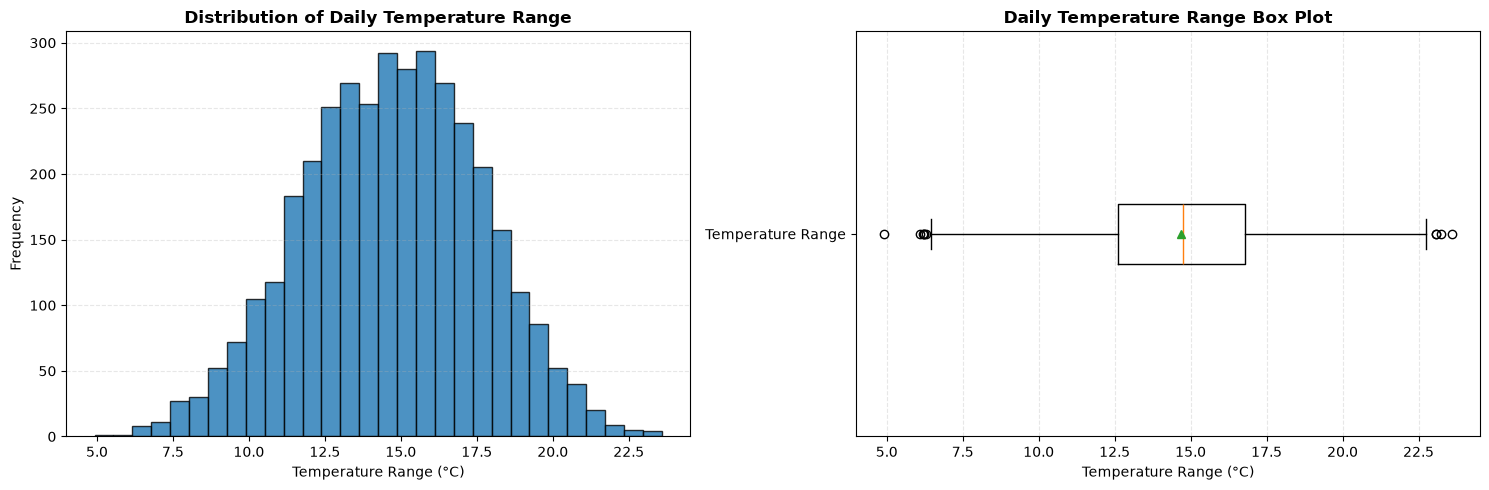

In [67]:
# Create two visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(
    weather_data_df["TEMP_RANGE"],
    bins=30,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title(
    "Distribution of Daily Temperature Range",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("Temperature Range (°C)")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# Box Plot
axes[1].boxplot(
    weather_data_df["TEMP_RANGE"],
    vert=False,
    showmeans=True
)

axes[1].set_title(
    "Daily Temperature Range Box Plot",
    fontsize=12,
    fontweight="bold"
)
axes[1].set_xlabel("Temperature Range (°C)")
axes[1].set_yticks([1])
axes[1].set_yticklabels(["Temperature Range"])
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* The average daily temperature range in Cairo was 14.69°C across the 2016–2025 period.
* The median temperature range was 14.74°C, indicating that the typical daily difference between maximum and minimum temperatures was approximately 14.7°C.
* The daily temperature range varied from 4.92°C to 23.59°C.
* The largest temperature range was recorded on May 5, 2019, at 23.59°C.
* The histogram and box plot help illustrate the distribution and variability of daily temperature ranges and identify observations that may require further investigation.
* Large daily temperature ranges


## 27. Data Quality Validation

Validate the quality and consistency of the weather dataset collected from Cairo between 2016 and 2025.

The validation process will check for physically implausible values and inconsistencies in the main weather variables.

The following conditions will be examined:

* Daily maximum temperature (`T2M_MAX`) must be greater than or equal to daily minimum temperature (`T2M_MIN`).
* Daily mean temperature (`T2M`) should fall between daily minimum and maximum temperatures.
* Relative humidity (`RH2M`) must be between 0% and 100%.
* Wind speed (`WS10M`) must be non-negative.
* Precipitation (`PRECTOTCORR`) must be non-negative.

This validation helps identify potential data quality issues before preparing the dataset for future weather forecasting.


In [68]:
# Validate temperature consistency
invalid_temperature_order = (
    weather_data_df["T2M_MAX"] < weather_data_df["T2M_MIN"]
)

invalid_mean_temperature = (
    (weather_data_df["T2M"] < weather_data_df["T2M_MIN"]) |
    (weather_data_df["T2M"] > weather_data_df["T2M_MAX"])
)

# Validate relative humidity
invalid_humidity = (
    (weather_data_df["RH2M"] < 0) |
    (weather_data_df["RH2M"] > 100)
)

# Validate wind speed
invalid_wind_speed = weather_data_df["WS10M"] < 0

# Validate precipitation
invalid_precipitation = weather_data_df["PRECTOTCORR"] < 0

# Display validation results
validation_results = pd.Series({
    "Maximum temperature below minimum temperature":
        invalid_temperature_order.sum(),
    "Mean temperature outside daily temperature range":
        invalid_mean_temperature.sum(),
    "Relative humidity outside 0–100%":
        invalid_humidity.sum(),
    "Negative wind speed":
        invalid_wind_speed.sum(),
    "Negative precipitation":
        invalid_precipitation.sum()
})

print("Data Quality Validation Results:")
print(validation_results.to_string())

print("\nTotal observations:", len(weather_data_df))

Data Quality Validation Results:
Maximum temperature below minimum temperature       0
Mean temperature outside daily temperature range    0
Relative humidity outside 0–100%                    0
Negative wind speed                                 0
Negative precipitation                              0

Total observations: 3653


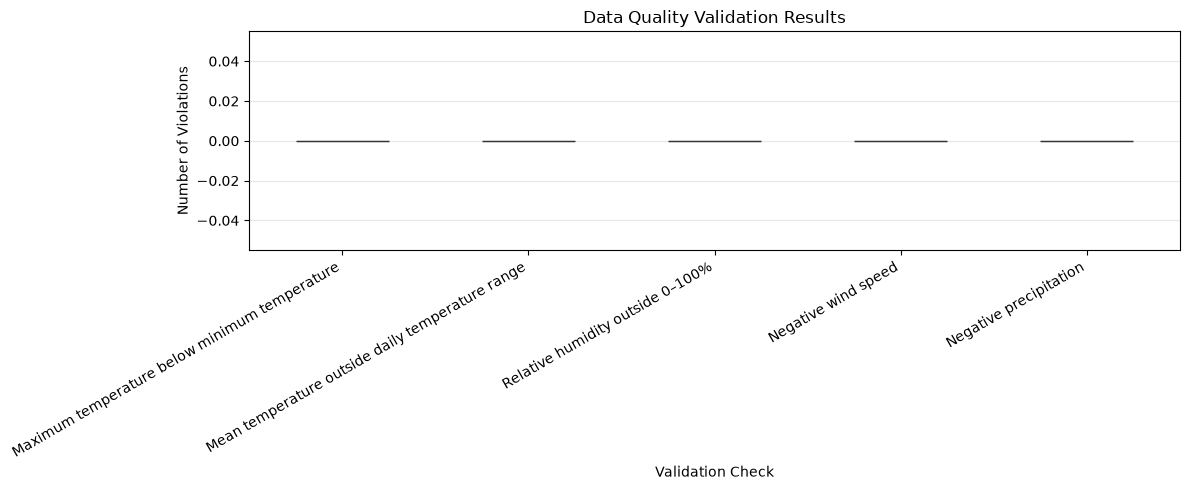

In [69]:
plt.figure(figsize=(12, 5))

validation_results.sort_values().plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Data Quality Validation Results")
plt.xlabel("Validation Check")
plt.ylabel("Number of Violations")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Findings

* No observations were found where the maximum temperature was lower than the minimum temperature.
* All daily mean temperature values fell within the corresponding minimum and maximum temperature range.
* Relative humidity values remained within the valid range of 0% to 100%.
* No negative wind speed or precipitation values were detected.
* The bar chart confirms that all five validation checks recorded zero violations.

Overall, the dataset passed all five logical consistency checks. However, passing these checks does not guarantee that every observation is meteorologically accurate, so extreme values may require further investigation.


## 28. Investigating Extreme Weather Observations

Investigate extreme weather observations to better understand the distribution and variability of the collected data.

This analysis focuses on maximum temperature, minimum temperature, mean temperature, precipitation, wind speed, and relative humidity.

Boxplots and time series visualizations will be used to identify potentially unusual observations and examine when they occurred.

Extreme values will not be removed automatically, as they may represent genuine weather events.


C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


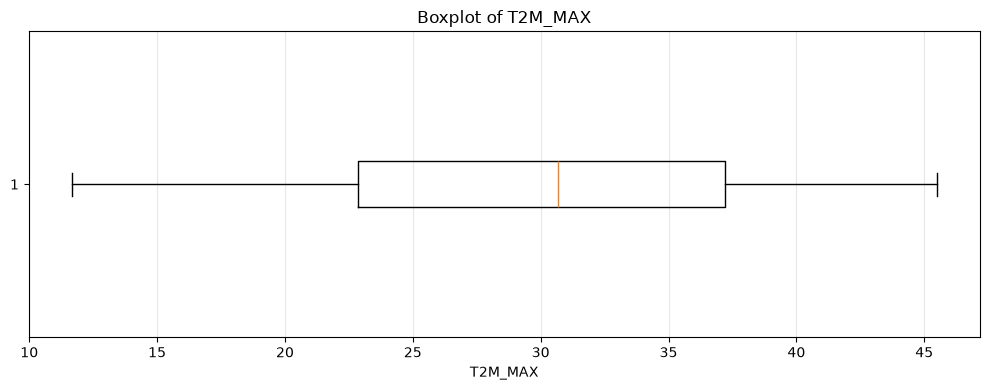

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


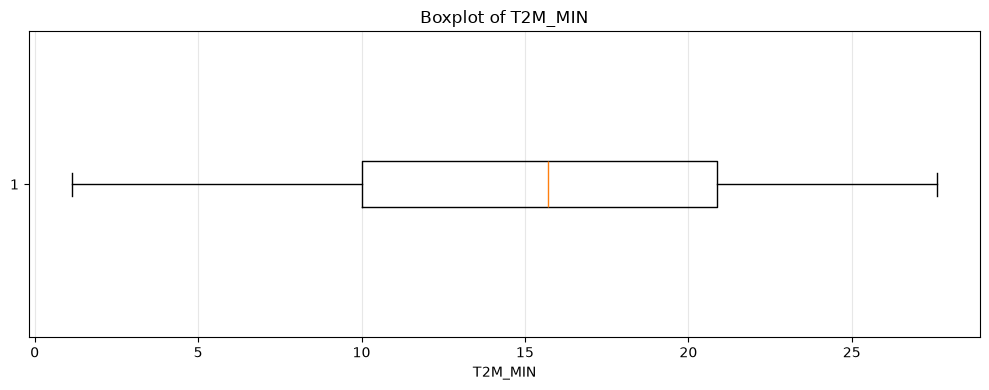

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


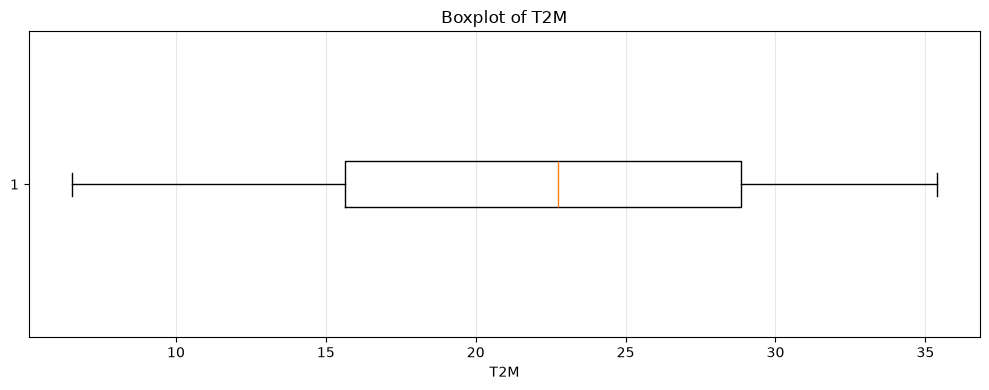

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


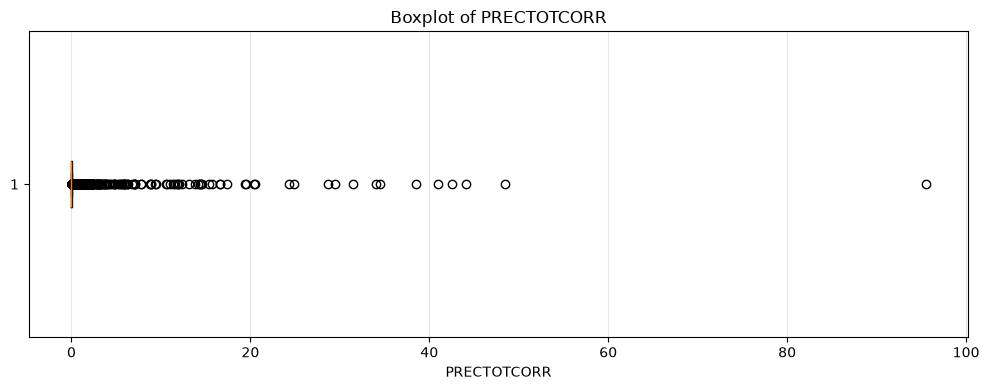

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


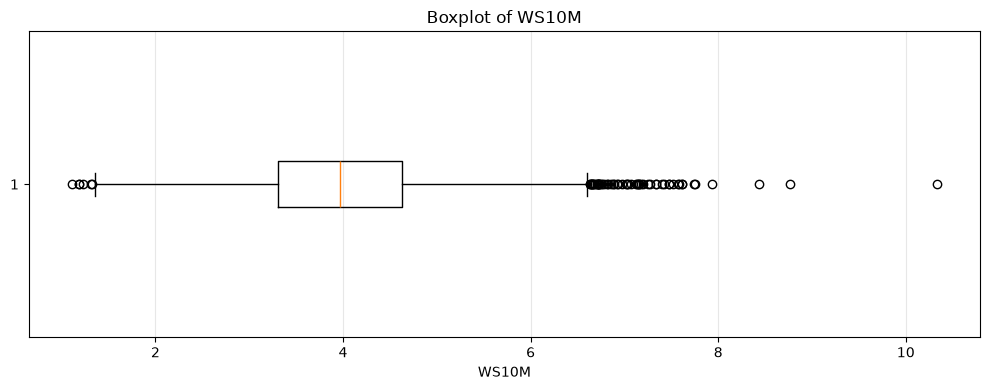

C:\Users\moham\AppData\Local\Temp\ipykernel_8756\793366387.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


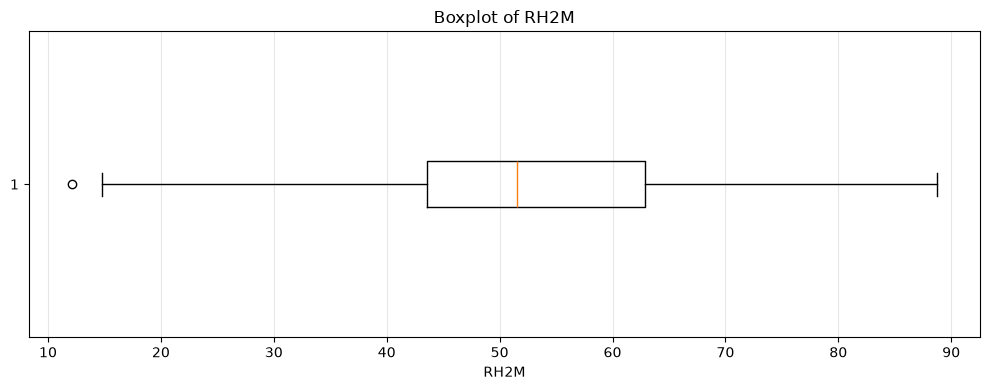

In [70]:
weather_variables = [
    "T2M_MAX",
    "T2M_MIN",
    "T2M",
    "PRECTOTCORR",
    "WS10M",
    "RH2M"
]

for column in weather_variables:
    plt.figure(figsize=(10, 4))

    plt.boxplot(
        weather_data_df[column].dropna(),
        vert=False
    )

    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

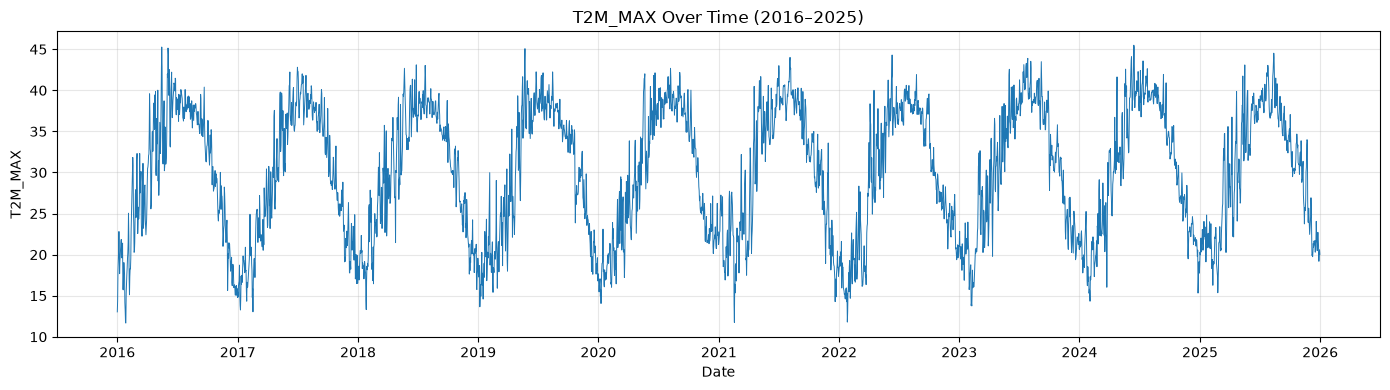

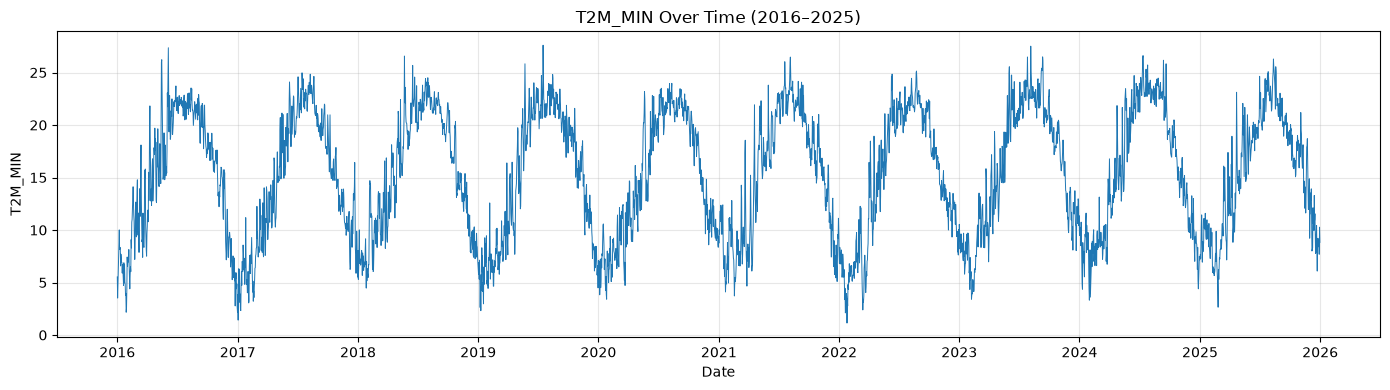

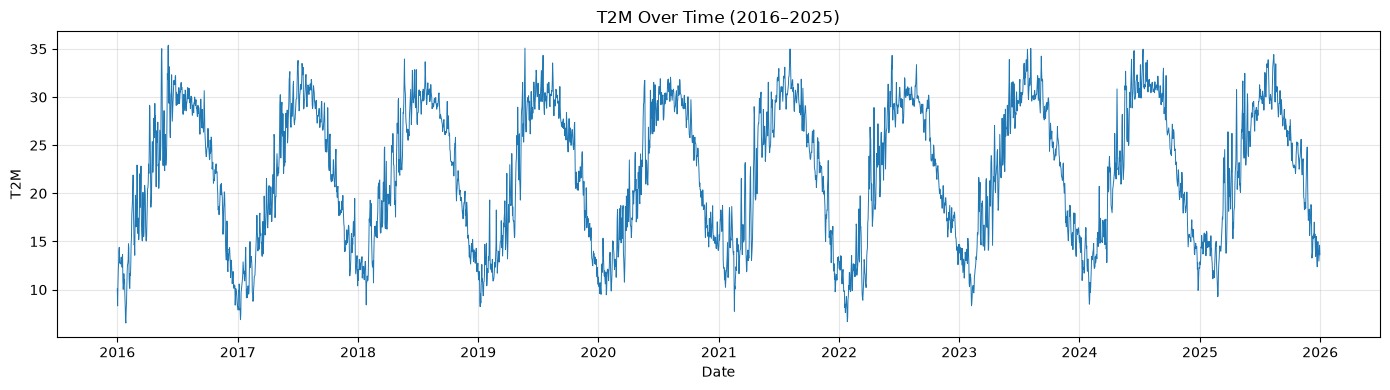

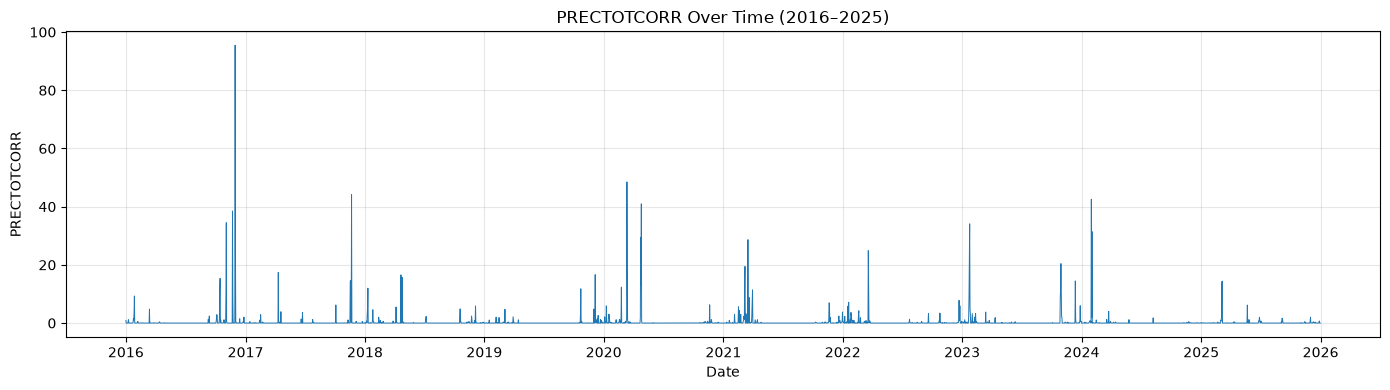

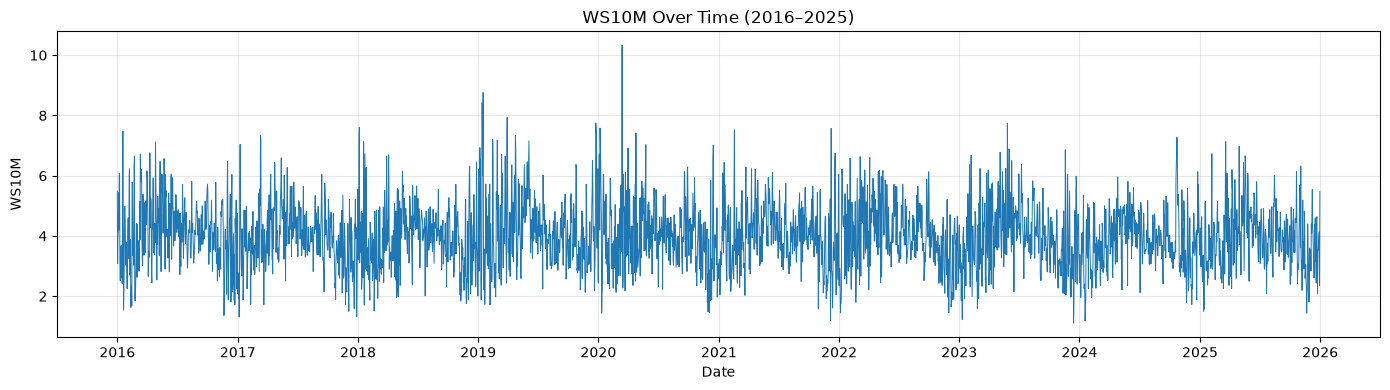

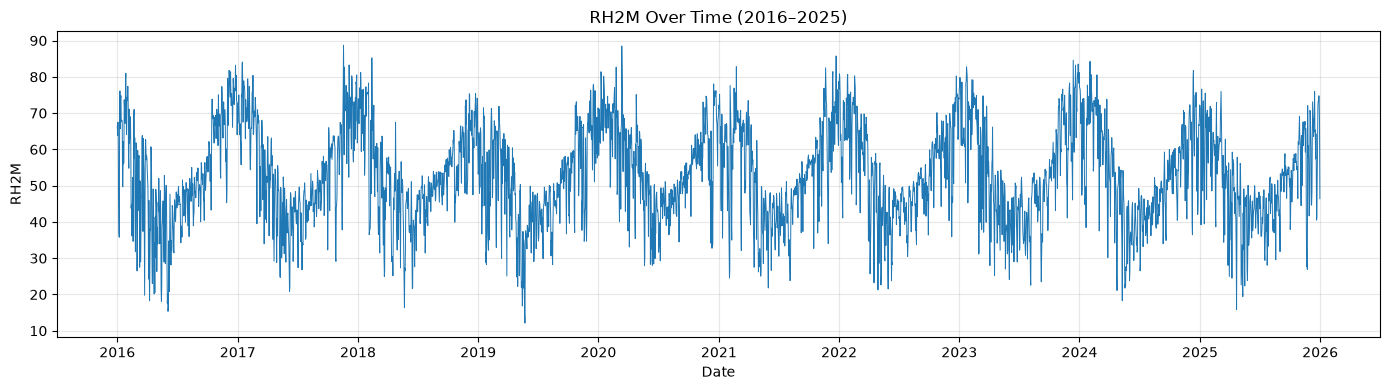

In [71]:
for column in weather_variables:
    plt.figure(figsize=(14, 4))

    plt.plot(
        weather_data_df["date"],
        weather_data_df[column],
        linewidth=0.7
    )

    plt.title(f"{column} Over Time (2016–2025)")
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()
    

### Findings

* **Temperature:** The time series plots show clear seasonal variations, with higher temperatures during summer and lower temperatures during winter.
* **Precipitation:** Most daily precipitation values are close to zero, with occasional large increases representing potentially heavy rainfall events.
* **Wind Speed:** Wind speed varies over time, with occasional high values that may represent stronger wind conditions.
* **Relative Humidity:** Humidity fluctuates throughout the year and shows variation across different seasons.
* **Potential Outliers:** The boxplots highlight observations that may be statistically unusual. However, these observations are not necessarily errors and should not be removed without further investigation.

Overall, the visualizations provide a useful overview of extreme observations and temporal variability. Further investigation may be required to determine whether specific extreme values are valid weather events.


## 29. Preparing the Clean Dataset

Prepare the weather dataset for further analysis and future forecasting tasks.

The preparation process will include reviewing the dataset structure, checking data types, verifying missing values, and confirming that the date column is properly formatted.

The original raw JSON file will remain unchanged, while the prepared dataset will be saved separately as a CSV file for future use.


In [72]:
# Review dataset structure
print("Dataset Shape:", weather_data_df.shape)

print("\nColumn Names:")
print(weather_data_df.columns.tolist())

print("\nData Types:")
print(weather_data_df.dtypes)

print("\nMissing Values:")
print(weather_data_df.isnull().sum())

print("\nDuplicate Dates:")
print(weather_data_df["date"].duplicated().sum())

print("\nDate Range:")
print("Start:", weather_data_df["date"].min())
print("End:", weather_data_df["date"].max())

print("\nFirst 5 Rows:")
display(weather_data_df.head())

Dataset Shape: (3653, 12)

Column Names:
['date', 'T2M_MAX', 'T2M_MIN', 'T2M', 'PRECTOTCORR', 'WS10M', 'RH2M', 'T2M_30D_ROLLING', 'year', 'month', 'is_rainy_day', 'TEMP_RANGE']

Data Types:
date               datetime64[us]
T2M_MAX                   float64
T2M_MIN                   float64
T2M                       float64
PRECTOTCORR               float64
WS10M                     float64
RH2M                      float64
T2M_30D_ROLLING           float64
year                        int32
month                       int32
is_rainy_day                 bool
TEMP_RANGE                float64
dtype: object

Missing Values:
date                0
T2M_MAX             0
T2M_MIN             0
T2M                 0
PRECTOTCORR         0
WS10M               0
RH2M                0
T2M_30D_ROLLING    29
year                0
month               0
is_rainy_day        0
TEMP_RANGE          0
dtype: int64

Duplicate Dates:
0

Date Range:
Start: 2016-01-01 00:00:00
End: 2025-12-31 00:00:00

First 5 

,date,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M,T2M_30D_ROLLING,year,month,is_rainy_day,TEMP_RANGE
0,2016-01-01,13.03,5.53,10.08,0.90,5.49,66.37,NaN,2016,1,True,7.50
1,2016-01-02,14.35,3.52,8.31,0.01,3.08,63.88,NaN,2016,1,True,10.83
2,2016-01-03,18.01,4.84,10.54,0.02,3.97,67.52,NaN,2016,1,True,13.17
3,2016-01-04,19.33,6.47,11.99,0.00,4.22,63.10,NaN,2016,1,False,12.86
4,2016-01-05,20.48,7.56,12.78,0.00,5.43,47.29,NaN,2016,1,False,12.92


### Reviewing Derived Columns

The dataset contains additional columns created during exploratory data analysis. These include rolling temperature averages, calendar features, rainy-day indicators, and daily temperature range.

Before exporting the dataset, review these derived features and distinguish them from the original weather variables to ensure the saved dataset remains suitable for future analysis and forecasting.


In [73]:
print("Dataset Shape:", weather_data_df.shape)

print("\nData Types:")
print(weather_data_df.dtypes)

print("\nMissing Values:")
print(weather_data_df.isnull().sum())

print("\nDuplicate Dates:")
print(weather_data_df["date"].duplicated().sum())

print("\nDate Range:")
print("Start:", weather_data_df["date"].min())
print("End:", weather_data_df["date"].max())

Dataset Shape: (3653, 12)

Data Types:
date               datetime64[us]
T2M_MAX                   float64
T2M_MIN                   float64
T2M                       float64
PRECTOTCORR               float64
WS10M                     float64
RH2M                      float64
T2M_30D_ROLLING           float64
year                        int32
month                       int32
is_rainy_day                 bool
TEMP_RANGE                float64
dtype: object

Missing Values:
date                0
T2M_MAX             0
T2M_MIN             0
T2M                 0
PRECTOTCORR         0
WS10M               0
RH2M                0
T2M_30D_ROLLING    29
year                0
month               0
is_rainy_day        0
TEMP_RANGE          0
dtype: int64

Duplicate Dates:
0

Date Range:
Start: 2016-01-01 00:00:00
End: 2025-12-31 00:00:00


## 30. Exporting the Prepared Dataset

Export the prepared weather dataset to a CSV file for future analysis and forecasting tasks.

The original weather observations will be preserved, including the derived features created during exploratory data analysis.

The 29 missing values in the 30-day rolling average will remain unchanged because they occur naturally at the beginning of the time series.

The raw JSON file will remain available as the original source data.


In [74]:
# Export the prepared dataset
output_file = "cairo_weather_prepared.csv"

weather_data_df.to_csv(
    output_file,
    index=False
)

print("Dataset exported successfully!")
print("File:", output_file)
print("Rows:", len(weather_data_df))
print("Columns:", len(weather_data_df.columns))

Dataset exported successfully!
File: cairo_weather_prepared.csv
Rows: 3653
Columns: 12


In [75]:
# Load the exported dataset
weather_data_check = pd.read_csv(
    "cairo_weather_prepared.csv",
    parse_dates=["date"]
)

print("Exported Dataset Shape:", weather_data_check.shape)
print("Missing Values:", weather_data_check.isnull().sum().sum())
print("Duplicate Dates:", weather_data_check["date"].duplicated().sum())

# Compare the original and exported dataset
print(
    "Dataset values preserved:",
    weather_data_check.equals(weather_data_df)
)

Exported Dataset Shape: (3653, 12)
Missing Values: 29
Duplicate Dates: 0
Dataset values preserved: False


## 31. Verifying Exported Data

Verify that the exported CSV file preserves the weather observations and derived features from the prepared DataFrame.

CSV files may represent dates and numeric values differently from their original in-memory data types. Therefore, the verification process will compare the exported data after normalizing compatible data types and handling floating-point precision.

The expected missing values in the 30-day rolling average will be preserved because they result from the rolling-window calculation.


In [76]:
# Compare data types
print("Original Data Types:")
print(weather_data_df.dtypes)

print("\nExported Data Types:")
print(weather_data_check.dtypes)

# Compare numeric columns with floating-point tolerance
numeric_columns = weather_data_df.select_dtypes(
    include="number"
).columns

numeric_match = (
    weather_data_df[numeric_columns].to_numpy()
    == weather_data_check[numeric_columns].to_numpy()
)

print("\nExact Numeric Matches:", numeric_match.all())

print(
    "Numeric Values Match Within Tolerance:",
    __import__("numpy").allclose(
        weather_data_df[numeric_columns].to_numpy(),
        weather_data_check[numeric_columns].to_numpy(),
        rtol=1e-9,
        atol=1e-9,
        equal_nan=True
    )
)

# Compare date columns
print(
    "\nDates Match:",
    weather_data_df["date"].equals(weather_data_check["date"])
)

# Compare Boolean column
print(
    "Rainy-Day Flags Match:",
    weather_data_df["is_rainy_day"].equals(
        weather_data_check["is_rainy_day"]
    )
)

Original Data Types:
date               datetime64[us]
T2M_MAX                   float64
T2M_MIN                   float64
T2M                       float64
PRECTOTCORR               float64
WS10M                     float64
RH2M                      float64
T2M_30D_ROLLING           float64
year                        int32
month                       int32
is_rainy_day                 bool
TEMP_RANGE                float64
dtype: object

Exported Data Types:
date               datetime64[us]
T2M_MAX                   float64
T2M_MIN                   float64
T2M                       float64
PRECTOTCORR               float64
WS10M                     float64
RH2M                      float64
T2M_30D_ROLLING           float64
year                        int64
month                       int64
is_rainy_day                 bool
TEMP_RANGE                float64
dtype: object

Exact Numeric Matches: False
Numeric Values Match Within Tolerance: True

Dates Match: True
Rainy-Day Flags Matc

### Findings

* The exported CSV contains all 3,653 observations and 12 columns.
* Numeric values match the original DataFrame within the specified floating-point tolerance.
* Date values and rainy-day indicators were preserved correctly.
* The `year` and `month` columns were inferred as `int64` instead of `int32` when the CSV was reloaded. This is a normal data type difference.
* The 29 missing values in `T2M_30D_ROLLING` were preserved as expected.

Overall, the export verification was successful, and the prepared dataset is ready for subsequent analysis and forecasting tasks.


## 32. Final Exploratory Data Analysis Summary

This section summarizes the main findings from the exploratory data analysis of daily weather observations collected for Cairo, Egypt, from January 2016 to December 2025.

The analysis covered data quality, temperature patterns, precipitation behavior, wind speed, relative humidity, temporal dependencies, and relationships between weather variables.

The summary highlights the most important observations and documents the dataset's readiness for future weather forecasting experiments.


In [77]:
print("=" * 55)
print("FINAL WEATHER DATA EDA SUMMARY")
print("=" * 55)

print(f"\nPeriod: {weather_data_df['date'].min().date()} to "
      f"{weather_data_df['date'].max().date()}")

print(f"Total observations: {len(weather_data_df)}")
print(f"Total columns: {len(weather_data_df.columns)}")

print("\n--- Data Quality ---")
print(f"Duplicate dates: {weather_data_df['date'].duplicated().sum()}")
print(f"Missing values in original weather variables: "
      f"{weather_data_df[['T2M_MAX', 'T2M_MIN', 'T2M', 'PRECTOTCORR', 'WS10M', 'RH2M']].isnull().sum().sum()}")

print("\n--- Temperature ---")
print(f"Average mean temperature: {weather_data_df['T2M'].mean():.2f} °C")
print(f"Highest recorded maximum temperature: {weather_data_df['T2M_MAX'].max():.2f} °C")
print(f"Lowest recorded minimum temperature: {weather_data_df['T2M_MIN'].min():.2f} °C")
print(f"Average daily temperature range: {weather_data_df['TEMP_RANGE'].mean():.2f} °C")

print("\n--- Precipitation ---")
print(f"Average daily precipitation: {weather_data_df['PRECTOTCORR'].mean():.3f} mm/day")
print(f"Maximum daily precipitation: {weather_data_df['PRECTOTCORR'].max():.2f} mm/day")
print(f"Rainy days: {weather_data_df['is_rainy_day'].sum()}")
print(f"Dry days: {(~weather_data_df['is_rainy_day']).sum()}")

print("\n--- Wind Speed ---")
print(f"Average wind speed: {weather_data_df['WS10M'].mean():.2f} m/s")
print(f"Maximum wind speed: {weather_data_df['WS10M'].max():.2f} m/s")

print("\n--- Relative Humidity ---")
print(f"Average relative humidity: {weather_data_df['RH2M'].mean():.2f}%")
print(f"Minimum relative humidity: {weather_data_df['RH2M'].min():.2f}%")
print(f"Maximum relative humidity: {weather_data_df['RH2M'].max():.2f}%")

FINAL WEATHER DATA EDA SUMMARY

Period: 2016-01-01 to 2025-12-31
Total observations: 3653
Total columns: 12

--- Data Quality ---
Duplicate dates: 0
Missing values in original weather variables: 0

--- Temperature ---
Average mean temperature: 22.10 °C
Highest recorded maximum temperature: 45.49 °C
Lowest recorded minimum temperature: 1.14 °C
Average daily temperature range: 14.69 °C

--- Precipitation ---
Average daily precipitation: 0.389 mm/day
Maximum daily precipitation: 95.48 mm/day
Rainy days: 929
Dry days: 2724

--- Wind Speed ---
Average wind speed: 4.00 m/s
Maximum wind speed: 10.33 m/s

--- Relative Humidity ---
Average relative humidity: 52.69%
Minimum relative humidity: 12.12%
Maximum relative humidity: 88.72%


### Final EDA Findings

**1. Dataset Quality**

* The dataset contains 3,653 daily observations covering January 2016 through December 2025.
* No duplicate dates or missing values were found in the six original weather variables.
* All five logical data quality checks passed without detecting violations.
* The 29 missing values in the 30-day rolling average are expected because a complete 30-day window is unavailable at the beginning of the series.

**2. Temperature Patterns**

* The average daily mean temperature was 22.10°C.
* The highest recorded daily maximum temperature was 45.49°C, while the lowest recorded daily minimum temperature was 1.14°C.
* The average daily temperature range was 14.69°C.
* Monthly and daily visualizations showed clear seasonal temperature variations.

**3. Precipitation Patterns**

* Average daily precipitation was 0.389 mm/day.
* The dataset contained 929 rainy days and 2,724 dry days, based on precipitation greater than zero.
* The maximum recorded daily precipitation was 95.48 mm/day.
* Precipitation was highly unevenly distributed, with many dry days and occasional large values.

**4. Wind Speed and Relative Humidity**

* Average wind speed was 4.00 m/s, with a maximum of 10.33 m/s.
* Average relative humidity was 52.69%, ranging from 12.12% to 88.72%.
* Both variables showed variability over time and potential extreme observations that should not be removed without further evidence.

**5. Time-Series Characteristics**

* Temperature exhibited strong seasonal patterns and high short-term autocorrelation.
* The ADF test rejected the unit-root null hypothesis for the analyzed mean-temperature series at the 5% significance level.
* Correlation analysis showed a strong positive relationship among temperature variables and negative correlations between temperature and relative humidity.

**6. Readiness for Forecasting**

* The prepared dataset was successfully exported to CSV and verified against the original DataFrame.
* The dataset provides a useful foundation for future weather forecasting experiments.
* Bef
